# Record repair and a frozen push screen: runnable demo

This notebook demonstrates the evaluation artifact **`art_sV0cQ3ef1ZRQ`**, "Record repair and a frozen push screen". It is Step 0 of iteration 4 of a study of *algorithm choice* in **Qwen3-8B**, with Llama-3.1-8B as the replication model. Ask the model to "implement a path search" and it writes BFS almost every time. Ask for the k-th smallest element and it sorts the whole list. The study asks whether prompt bans ("do not use X"), novelty instructions, token vetoes or activation pushes (a direction added to the residual stream) move the model off this default, and which algorithm it lands on.

The artifact runs on CPU and generates no model text. Every number is recomputed from the **labelled rows** of 11 earlier experiments: one row per generated program, labelled with the algorithm it implements and whether it passes the hidden tests. Its entry point, `eval.py`, runs 14 stages. This demo runs the three that the curated data supports end to end, with the original code split into cells:

| Stage | What it computes | Original code |
|---|---|---|
| `rows` | The unified labelled-program table | `src/rows.py` (here rebuilt from `mini_demo_data.json`) |
| `knob` | The **knob table**: one row per experiment × task × arm × dial cell, with correct-only rarefied Hill-1 and 90% CIs, Good's coverage, pass cost against the cell's own twin, and escape/qualify flags | `src/knob.py`, `src/stats.py` |
| `screen` | The frozen **push-movability screen** (`screen.json` and its sha256), the random-direction counts, Table 110, the 27 verification targets and the per-task verdicts | `src/screen.py`, `screen_rule.py` |

**Vocabulary**
- **Task**: a coding problem. T03 is k-th smallest, T05 two sum, T06 find duplicate, T10 connected components, T1 unweighted path search, T2 weighted shortest path, and so on. Each task has a **default**, Qwen's modal algorithm (BFS for T1, for example), and a **catalogue** of known algorithm modes.
- **Arm**: one experimental condition. For example, `ban` is a modal "do not use X" prompt, and `RAND9001_a1.0` is a norm-matched random direction added at strength α = 1. Each arm is priced against its own neutral **twin**.
- **Off-default share**: `offdef = 1 − n_default / n_attempted`. **Pass rate**: `n_passed / n`. **Pass cost**: 100 × (pass_twin − pass_arm) points, with a Newcombe 95% interval.
- **Hill-1 at depth 25** (`H1r25`): the effective number of distinct algorithms among the *correct* programs, rarefied to 25 programs. A value of 1.0 means one algorithm; 2.0 means two equally common ones.
- **Escape** (the screen rule): a direction escapes if `offdef(d) − offdef(twin) ≥ 0.20` and `pass(d) ≥ 0.8 × pass(twin)`. A task is **movable** if some direction escapes at α ≤ 2. The screen predicts that movable tasks have a catalogue-only modal-ban avoidance of at least 0.5.

**Expected results at the original settings**
- Every recomputed knob cell matches the recorded table.
- The screen's sha256 equals the frozen `d6a2ca97…`.
- The movable tasks are T03, T05, T06, T1, T10 and T2.
- The movable × avoidance table is 6/0/0/8 (one-sided Fisher p = 1/3003). This is a descriptive screen, not a confirmation.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the version the artifact pinned)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib, pyarrow — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pyarrow==18.1.0')

In [2]:
from __future__ import annotations

# eval.py
import argparse
import json
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# src/stages.py, src/stats.py, src/labels.py, src/knob.py, src/screen.py
import hashlib
import importlib.util
import itertools
import math
import multiprocessing as mp
import re
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from functools import lru_cache
from typing import Any, Iterable, Sequence

import numpy as np
import pandas as pd
from scipy import stats as sps

# notebook additions: a namespace for the unit checks, a subprocess for the standalone screen rule, plotting
import subprocess
from types import SimpleNamespace

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-4/evaluation-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
pd.set_option("display.max_colwidth", 110)  # notebook display settings for the tables below
pd.set_option("display.width", 200)
EXAMPLES = data["datasets"][0]["examples"]  # one example per task of the push_screen dataset
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EXAMPLES)} task examples, {data['metadata']['n_cells']} knob cells, "
      f"{data['metadata']['n_programs']} labelled programs")
for ex in EXAMPLES:
    print(f"  {ex['task']:>4}  default={ex['qwen_default']:<14} cells={ex['n_cells']:>3}  programs={ex['n_programs']:>5}"
          f"  | recorded: {ex['output']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'push_screen': 14 task examples, 174 knob cells, 10050 labelled programs
   T03  default=full_sort      cells= 30  programs= 1600  | recorded: movable=1; E_t(a1)=0.4444; E_t(a2)=1.0; push_top1=quickselect; cat-only ban avoidance=0.97
   T04  default=naive          cells= 15  programs=  850  | recorded: movable=0; E_t(a1)=0.0; E_t(a2)=0.0; push_top1=None; cat-only ban avoidance=0.4
   T05  default=hash_map       cells= 14  programs=  800  | recorded: movable=1; E_t(a1)=0.0; E_t(a2)=0.6667; push_top1=brute_force; cat-only ban avoidance=0.86
   T06  default=hash_set       cells= 15  programs=  850  | recorded: movable=1; E_t(a1)=0.0; E_t(a2)=0.3333; push_top1=sort_adjacent; cat-only ban avoidance=0.79
   T08  default=iteration      cells=  7  programs=  400  | recorded: movable=0; E_t(a1)=0.0; E_t(a2)=None; push_top1=None; cat-only ban avoidance=0.01
   T10  default=union_find     cells=  8  progra

## Configuration

All tunable parameters are set here. The knob statistics are Monte-Carlo estimates:
- Each Hill-1 value is the mean over `N_RAREFY` random subsamples of 25 correct programs.
- Each 90% interval uses `N_BOOT` bootstrap replicates, and each replicate is rarefied with `N_BOOT_RAREFY` subsamples.

The values below are the artifact's original ones from `src/stats.py`. At these values every recomputed cell matches the recorded knob table exactly, and the three stages take about 5 seconds on two CPU cores. For a quicker smoke test, lower the three Monte-Carlo sizes (for example to 1 / 2 / 1). The Hill-1 values and intervals then change in their later digits. The screen hash does not change, because the screen rule reads only counts.

`DEPTH`, `DEPTH_LOW` and `MASTER_SEED` define the statistic rather than the size of the run. Keep them fixed to reproduce the record.

In [5]:
# Monte-Carlo sizes of the knob statistics (src/stats.py). Original values: 1000 / 1000 / 200.
N_RAREFY = 1000         # rarefaction subsamples averaged into each Hill-1 value
N_BOOT = 1000           # bootstrap replicates behind each 90% interval
N_BOOT_RAREFY = 200     # rarefaction subsamples inside each bootstrap replicate

# Definitions of the statistic (not run-size knobs): keep fixed to reproduce the record
DEPTH = 25              # rarefaction depth: correct programs per cell
DEPTH_LOW = 10          # secondary depth, reported for cells with fewer than 25 correct programs
MASTER_SEED = 20261021  # each cell's seed is int(sha256('20261021|' + cell_id)[:8], 16)

# Run settings
MEMORY_LIMIT_GB = 18.0                    # eval.py caps the address space (RLIMIT_AS) at 18 GB; None skips the cap
DEMO_STAGES = ["rows", "knob", "screen"]  # = uv run eval.py --stages rows,knob,screen
WS = Path("eval_demo_outputs")            # stands in for the artifact folder: data/, tables/, results/, screen*.json

## The `eval.py` entry point

`eval.py` does four things:
1. Sets up loguru logging to stdout and to `logs/eval.log`.
2. Caps the address space at 18 GB.
3. Picks the stages to run from `--stages`.
4. Runs those stages in order and times each one.

Each stage reads what the earlier stages wrote to `data/` and `results/`. Here the loop body becomes `run_stage()`, and each section calls it once its stage function is defined. Calling `run_stage("rows")`, `run_stage("knob")` and `run_stage("screen")` in turn does the same as `uv run eval.py --stages rows,knob,screen`.

In [6]:
WS.mkdir(parents=True, exist_ok=True)
(WS / "logs").mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(WS / "logs" / "eval.log", rotation="30 MB", level="DEBUG")

STAGES = ["inventory", "rows", "judges", "knob", "screen", "route", "llama", "other", "figures", "rigor", "wording", "rivals",
          "audit", "outputs"]


def _limit_memory(gb: float = 18.0) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def run_stage(st: str) -> None:
    """One pass of eval.py's main() loop. eval.py looks the stage up in src/stages.py (getattr(S, f"stage_{st}"));
    here the stage functions are defined in the notebook sections below."""
    t0 = time.time()
    logger.info(f"=== stage {st} ===")
    globals()[f"stage_{st}"]()
    logger.info(f"=== stage {st} done in {time.time() - t0:.1f}s ===")


# eval.py main(): stages = STAGES if args.stages == "all" else [s.strip() for s in args.stages.split(",")]
if MEMORY_LIMIT_GB:
    _limit_memory(MEMORY_LIMIT_GB)
print("eval.py stages:", ", ".join(STAGES))
print("run here:      ", ", ".join(DEMO_STAGES))

eval.py stages: inventory, rows, judges, knob, screen, route, llama, other, figures, rigor, wording, rivals, audit, outputs
run here:       rows, knob, screen


## Provenance: artifact ids and citations (`src/paths.py`, `src/stages.py`)

Every output cites its source as `<artifact_id>:<relative path>`, never as an absolute path. The 11 dependency artifacts are listed below.

On the run server, `root()` and `p()` find each dependency's folder on disk. This demo has no dependency folders, so those two functions are left out. Every file the three stages would read is instead a field of `mini_demo_data.json`.

`src/stages.py` also creates the output folders inside the workspace, which is `WS` here.

In [7]:
# src/paths.py — artifact id -> (root env var, workspace folder, short experiment name)
ARTIFACTS: dict[str, tuple[str, str, str]] = {
    "art_U5UKkFrOgSsE": ("AII_ITER1", "gen_art_experiment_4", "exp4"),
    "art_UoCVh2Qe5RZ0": ("AII_ITER1", "gen_art_experiment_6", "exp6"),
    "art_6zBfl3kDjeiP": ("AII_ITER2", "gen_art_experiment_7", "exp7"),
    "art_IVZc3TWCeE9f": ("AII_ITER2", "gen_art_experiment_9", "exp9"),
    "art_0ndRfWKBWclR": ("AII_ITER2", "gen_art_experiment_11", "exp11"),
    "art_1AYTO1Epb_7t": ("AII_ITER3", "gen_art_experiment_13", "exp13"),
    "art_WiY4wqHLb9Gy": ("AII_ITER3", "gen_art_experiment_14", "exp14"),
    "art_Q-qh-9HhPoWo": ("AII_ITER3", "gen_art_experiment_15", "exp15"),
    "art__5akZ9W9iZM4": ("AII_ITER3", "gen_art_experiment_16", "exp16"),
    "art_pVlCZ272hDV7": ("AII_ITER3", "gen_art_experiment_17", "exp17"),
    "art_ccAbfJVcv0LO": ("AII_ITER3", "gen_art_experiment_18", "exp18"),
}
BY_EXP = {v[2]: k for k, v in ARTIFACTS.items()}


def cite(exp_or_aid: str, rel: str) -> str:
    aid = BY_EXP.get(exp_or_aid, exp_or_aid)
    return f"{aid}:{rel}"


def exp_name(aid: str) -> str:
    return ARTIFACTS[aid][2]


# src/stages.py — output folders inside the workspace
DATA = WS / "data"
RES = WS / "results"
TAB = WS / "tables"
for _d in (DATA, RES, TAB, WS / "figures", WS / "audit"):
    _d.mkdir(exist_ok=True)

n_demo_cells = Counter(exp_name(c["artifact_id"]) for ex in EXAMPLES for c in ex["cells"])
for aid, (_, folder, exp) in ARTIFACTS.items():
    print(f"{exp:>6}  {aid}  {folder:<22}  cells in the demo data: {n_demo_cells.get(exp, 0)}")

  exp4  art_U5UKkFrOgSsE  gen_art_experiment_4    cells in the demo data: 3
  exp6  art_UoCVh2Qe5RZ0  gen_art_experiment_6    cells in the demo data: 2
  exp7  art_6zBfl3kDjeiP  gen_art_experiment_7    cells in the demo data: 0
  exp9  art_IVZc3TWCeE9f  gen_art_experiment_9    cells in the demo data: 4
 exp11  art_0ndRfWKBWclR  gen_art_experiment_11   cells in the demo data: 0
 exp13  art_1AYTO1Epb_7t  gen_art_experiment_13   cells in the demo data: 81
 exp14  art_WiY4wqHLb9Gy  gen_art_experiment_14   cells in the demo data: 0
 exp15  art_Q-qh-9HhPoWo  gen_art_experiment_15   cells in the demo data: 0
 exp16  art__5akZ9W9iZM4  gen_art_experiment_16   cells in the demo data: 0
 exp17  art_pVlCZ272hDV7  gen_art_experiment_17   cells in the demo data: 84
 exp18  art_ccAbfJVcv0LO  gen_art_experiment_18   cells in the demo data: 0


## Statistics I: rarefied Hill-1 and coverage (`src/stats.py`)

For a cell, take the algorithm labels of its **correct** programs and count them per algorithm.
- **Hill-1** is `exp(Shannon entropy)` of those counts: the effective number of algorithms.
- Cells have different numbers of correct programs. **Rarefaction** makes them comparable: the value is the mean Hill-1 over `N_RAREFY` subsamples of exactly `DEPTH = 25` programs, drawn without replacement (multivariate hypergeometric).
- **Good's coverage** is `1 − singletons / n`: the estimated share of the cell's output distribution that the sample has already seen.

`h1r_cell()` adds two 90% percentile intervals:
- An **iid program bootstrap**: resample the counts multinomially, then rarefy.
- A **template-cluster bootstrap**: resample the 5 prompt templates. It is used when all 5 templates have at least 5 correct programs.

Every cell has its own seed, `sha256('20261021|<cell id>')`, so the results do not depend on the order in which cells are processed. The constants are set in the configuration cell.

In [8]:
# MASTER_SEED, DEPTH, DEPTH_LOW, N_RAREFY, N_BOOT, N_BOOT_RAREFY: set in the configuration cell


def cell_seed(cell_id: str) -> int:
    return int(hashlib.sha256(f"{MASTER_SEED}|{cell_id}".encode()).hexdigest()[:8], 16)


def hill1_counts(x: np.ndarray) -> float:
    x = np.asarray(x, float)
    x = x[x > 0]
    if x.sum() <= 0:
        return float("nan")
    q = x / x.sum()
    return float(math.exp(-(q * np.log(q)).sum()))


def _hill1_rows(draws: np.ndarray, depth: int) -> np.ndarray:
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = np.where(q > 0, q * np.log(np.where(q > 0, q, 1.0)), 0.0).sum(axis=1)
    return np.exp(-h)


def rarefied_hill1(counts: Sequence[int], depth: int, n_draws: int, rng: np.random.Generator) -> float:
    c = np.asarray([int(v) for v in counts if int(v) > 0], np.int64)
    if c.sum() < depth or len(c) == 0:
        return float("nan")
    if len(c) == 1:
        return 1.0
    if c.sum() == depth:
        return hill1_counts(c)
    d = rng.multivariate_hypergeometric(c, depth, size=n_draws, method="marginals")
    return float(_hill1_rows(d, depth).mean())


def goods_coverage(counts: Sequence[int]) -> float:
    c = np.asarray([v for v in counts if v > 0])
    n = c.sum()
    if n == 0:
        return float("nan")
    f1 = int((c == 1).sum())
    return float(1 - f1 / n)


def expected_coverage_at(counts: Sequence[int], m: int) -> float:
    """Expected sample coverage of a size-m subsample (interpolation, Chao & Jost 2012 eq. 4a)."""
    c = np.asarray([v for v in counts if v > 0], float)
    n = int(c.sum())
    if m >= n:
        return goods_coverage(c)
    tot = 0.0
    for xi in c:
        if n - xi >= m:
            # C(n - xi, m) / C(n - 1, m)
            tot += (xi / n) * math.exp(math.lgamma(n - xi + 1) - math.lgamma(n - xi - m + 1)
                                       - math.lgamma(n) + math.lgamma(n - m))
    return float(1 - tot)


def coverage_standardised_hill1(counts: Sequence[int], target_cov: float, rng: np.random.Generator,
                                n_draws: int = 400) -> tuple[float, int]:
    """Hill-1 rarefied to the size m whose expected coverage first reaches target_cov (interpolation only)."""
    c = [int(v) for v in counts if v > 0]
    n = sum(c)
    if n == 0 or not np.isfinite(target_cov):
        return float("nan"), 0
    m_star = n
    for m in range(1, n + 1):
        if expected_coverage_at(c, m) >= target_cov - 1e-12:
            m_star = m
            break
    return rarefied_hill1(c, m_star, n_draws, rng), m_star


def h1r_cell(correct_labels: Sequence[str], templates: Sequence[str] | None, cell_id: str, depth: int = DEPTH,
             drop: Iterable[str] = (), n_boot: int = N_BOOT, n_boot_rarefy: int = N_BOOT_RAREFY,
             with_ci: bool = True) -> dict:
    """Correct-only rarefied Hill-1 for one cell; percentile CIs (template-cluster when eligible, and iid)."""
    drop = set(drop)
    keep = [i for i, l in enumerate(correct_labels) if l not in drop]
    labs = [correct_labels[i] for i in keep]
    tpls = [templates[i] for i in keep] if templates is not None else None
    cats = sorted(set(labs))
    idx = {c: i for i, c in enumerate(cats)}
    counts = np.zeros(len(cats), np.int64)
    for l in labs:
        counts[idx[l]] += 1
    n_c = int(counts.sum())
    rng = np.random.default_rng(cell_seed(f"{cell_id}|d{depth}|{'-'.join(sorted(drop))}"))
    out = {"n_c": n_c, "S_obs": int((counts > 0).sum()), "coverage": goods_coverage(counts),
           "value": rarefied_hill1(counts, depth, N_RAREFY, rng), "ci90": [float("nan")] * 2,
           "ci90_iid": [float("nan")] * 2, "ci_unit": None}
    if not with_ci or n_c < depth or len(cats) <= 1:
        if n_c >= depth and len(cats) == 1:
            out["ci90"] = [1.0, 1.0]
            out["ci90_iid"] = [1.0, 1.0]
            out["ci_unit"] = "degenerate"
        return out
    # iid program bootstrap
    probs = counts / n_c
    vals = np.full(n_boot, np.nan)
    for b in range(n_boot):
        cb = rng.multinomial(n_c, probs)
        vals[b] = rarefied_hill1(cb, depth, n_boot_rarefy, rng)
    out["ci90_iid"] = [float(np.nanquantile(vals, 0.05)), float(np.nanquantile(vals, 0.95))]
    out["ci90"] = list(out["ci90_iid"])
    out["ci_unit"] = "program"
    if tpls is not None:
        by_t: dict[str, np.ndarray] = {}
        for l, t in zip(labs, tpls):
            by_t.setdefault(str(t), np.zeros(len(cats), np.int64))[idx[l]] += 1
        tkeys = sorted(by_t)
        if len(tkeys) == 5 and all(by_t[t].sum() >= 5 for t in tkeys):
            mat = np.stack([by_t[t] for t in tkeys])
            tv = np.full(n_boot, np.nan)
            for b in range(n_boot):
                pick = rng.integers(0, len(tkeys), len(tkeys))
                tv[b] = rarefied_hill1(mat[pick].sum(0), depth, n_boot_rarefy, rng)
            if np.isfinite(tv).sum() > 0.5 * n_boot:
                out["ci90"] = [float(np.nanquantile(tv, 0.05)), float(np.nanquantile(tv, 0.95))]
                out["ci_unit"] = "template(5 clusters; few-cluster)"
    return out

## Statistics II: intervals and tests (`src/stats.py`)

The rest of the module falls into three groups:
- **Wilson** intervals and the **Newcombe** hybrid-score interval for a difference of two proportions. The pass cost uses Newcombe.
- **Fisher's exact test**, **balanced accuracy** and the zero-of-K upper bound `1 − 0.1^(1/K)`. The screen's summary uses these.
- The **Poisson-binomial** tail, permutation **Spearman**, **Holm**, **jackknife**, **Cohen's κ** and the base-2 **Jensen-Shannon** divergence. These belong to the route, llama, other and rivals stages, which this demo does not run. The unit checks further down still exercise them.

In [9]:
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return float("nan"), float("nan")
    ph = k / n
    den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe_diff(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """p1 - p2 with the Newcombe (1998, method 10) hybrid-score 95% interval."""
    if n1 <= 0 or n2 <= 0:
        return float("nan"), float("nan"), float("nan")
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


def poisson_binomial_sf(k: int, probs: Sequence[float]) -> float:
    """P(X >= k) for X = sum of independent Bernoulli(p_i), by dynamic programming."""
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for pi in probs:
        dist[1:] = dist[1:] * (1 - pi) + dist[:-1] * pi
        dist[0] *= (1 - pi)
    return float(dist[k:].sum())


def binom_sf(k: int, n: int, p0: float) -> float:
    return float(sps.binom.sf(k - 1, n, p0))


def _rank(a: np.ndarray) -> np.ndarray:
    return sps.rankdata(a)


def spearman_perm(x: Sequence[float], y: Sequence[float], n_perm: int = 1_000_000, seed: int = MASTER_SEED) -> dict:
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    n = len(x)
    if n < 3 or np.all(x == x[0]) or np.all(y == y[0]):
        return {"rho": float("nan"), "p_perm": float("nan"), "n": n, "method": "undefined"}
    rx, ry = _rank(x), _rank(y)
    rx = (rx - rx.mean()) / np.sqrt(((rx - rx.mean()) ** 2).sum())
    ry = (ry - ry.mean()) / np.sqrt(((ry - ry.mean()) ** 2).sum())
    rho = float((rx * ry).sum())
    if n <= 9:
        perms = np.array(list(itertools.permutations(range(n))))
        null = (rx[None, :] * ry[perms]).sum(1)
        method = f"exact enumeration ({len(perms)} permutations)"
    else:
        rng = np.random.default_rng(seed)
        null = np.empty(n_perm)
        chunk = 100_000
        for s in range(0, n_perm, chunk):
            m = min(chunk, n_perm - s)
            idx = np.argsort(rng.random((m, n)), axis=1)
            null[s:s + m] = (rx[None, :] * ry[idx]).sum(1)
        method = f"Monte Carlo permutation ({n_perm} draws)"
    p = float((np.abs(null) >= abs(rho) - 1e-12).mean())
    tau = sps.kendalltau(x, y)
    return {"rho": rho, "p_perm": p, "n": n, "method": method, "kendall_tau_b": float(tau.statistic),
            "kendall_p": float(tau.pvalue)}


def holm(pvals: Sequence[float]) -> list[float]:
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    m = len(order)
    run = 0.0
    for i, j in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[j]))
        out[j] = run
    return out.tolist()


def jackknife_ci(theta: float, jack_vals: Sequence[float], level: float = 0.95) -> list[float]:
    j = np.asarray(jack_vals, float)
    n = len(j)
    if n < 3:
        return [float("nan"), float("nan")]
    se = math.sqrt((n - 1) / n * ((j - j.mean()) ** 2).sum())
    tq = sps.t.ppf(0.5 + level / 2, n - 1)
    return [theta - tq * se, theta + tq * se]


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    a, b = list(a), list(b)
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else float("nan")


def kappa_boot_ci(a: Sequence[str], b: Sequence[str], n_boot: int = 2000, seed: int = MASTER_SEED) -> list[float]:
    a, b = list(a), list(b)
    n = len(a)
    if n < 3:
        return [float("nan"), float("nan")]
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)
        vals.append(cohen_kappa([a[i] for i in ix], [b[i] for i in ix]))
    v = np.asarray(vals, float)
    v = v[np.isfinite(v)]
    return [float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))] if len(v) else [float("nan")] * 2


def balanced_accuracy(pred: Sequence[int], truth: Sequence[int]) -> float:
    pred, truth = np.asarray(pred), np.asarray(truth)
    pos, neg = truth == 1, truth == 0
    if pos.sum() == 0 or neg.sum() == 0:
        return float("nan")
    return float(0.5 * ((pred[pos] == 1).mean() + (pred[neg] == 0).mean()))


def fisher_2x2(pred: Sequence[int], truth: Sequence[int], alternative: str = "two-sided") -> dict:
    pred, truth = np.asarray(pred), np.asarray(truth)
    tab = [[int(((pred == 1) & (truth == 1)).sum()), int(((pred == 1) & (truth == 0)).sum())],
           [int(((pred == 0) & (truth == 1)).sum()), int(((pred == 0) & (truth == 0)).sum())]]
    res = sps.fisher_exact(tab, alternative=alternative)
    return {"table": tab, "p": float(res.pvalue), "alternative": alternative}


def js_div2(p: np.ndarray, q: np.ndarray) -> float:
    """Base-2 Jensen-Shannon divergence (exp16 convention)."""
    p = np.asarray(p, float) / np.sum(p)
    q = np.asarray(q, float) / np.sum(q)
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def upper_bound_zero_of_k(k: int, level: float = 0.90) -> float:
    """One-sided upper bound on a per-direction escape probability when 0 of k escape."""
    return float(1 - (1 - level) ** (1 / k)) if k > 0 else float("nan")


# a worked example: pass cost of the T03 modal ban against its twin, as the knob stage computes it
_ban = next(c for ex in EXAMPLES if ex["task"] == "T03" for c in ex["cells"] if c["arm"] == "ban")
_twin = next(c for ex in EXAMPLES if ex["task"] == "T03" for c in ex["cells"]
             if c["artifact_id"] == _ban["artifact_id"] and c["arm"] == "twin")
_d, _lo, _hi = newcombe_diff(sum(_twin["programs"]["passed"]), len(_twin["programs"]["passed"]),
                             sum(_ban["programs"]["passed"]), len(_ban["programs"]["passed"]))
print(f"T03 ban vs twin: pass cost {100 * _d:.1f} pts, Newcombe 95% CI [{100 * _lo:.2f}, {100 * _hi:.2f}]")

T03 ban vs twin: pass cost 8.0 pts, Newcombe 95% CI [-0.13, 15.00]


## Labels: catalogues and defaults (`src/labels.py`, step G1)

Frozen labels are used exactly as recorded. Only spellings are aliased, for example `bellman_ford_spfa` → `bf_spfa`.

Where each task's catalogue comes from:
- **Bench tasks**: exp11's `bench/<task>/spec.json`. The demo data carries those catalogue entries as `spec_catalogue`, and `spec()` reads them from there.
- **T1**: exp9's 7-mode catalogue, plus iteration 1's `dijkstra_unit`, which is kept verbatim and flagged.
- **T2**: `dijkstra, bf_spfa, bidijkstra, floyd, dial`.

`QWEN_DEFAULT` holds Qwen's modal algorithm for each task. This is the "default" that bans and pushes try to move the model away from.

In [10]:
BENCH_DIRS = {
    "T03": "T03_kth_smallest", "T04": "T04_substring_search", "T05": "T05_two_sum", "T06": "T06_find_duplicate",
    "T08": "T08_fibonacci", "T10": "T10_connected_components", "T11": "T11_longest_increasing_subsequence",
    "T13": "T13_merge_intervals", "T14": "T14_top_k_frequent", "R1": "R1_non_overlapping_intervals",
    "R2": "R2_cycle_detection", "R3": "R3_topological_order", "R6": "R6_first_last_position",
}
BENCH12 = ["T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R3", "R6"]
PATH_TASKS = ["T1", "T2"]
QWEN14 = BENCH12 + PATH_TASKS

T1_CATALOGUE = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "idastar", "dijkstra_unit"]
T2_CATALOGUE = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]

# iteration-1/2 spellings -> canonical
ALIASES = {
    "bellman_ford_spfa": "bf_spfa", "bidirectional_bfs": "bibfs", "floyd_warshall": "floyd",
    "bidirectional_dijkstra": "bidijkstra", "astar_greedy": "astar", "astar_gbfs": "astar",
}
# labels that are not an attempted program (no code / unparseable / unresolved)
NOT_ATTEMPTED = {"invalid", "no_code", "unparseable", "disputed", "unresolved", "extraction_failed", "", "none", "None"}
NON_CATALOGUE_KEEP = {"other", "builtin", "unknown", "invalid", "no_code", "unparseable", "disputed", "unresolved"}

QWEN_DEFAULT = {
    "T03": "full_sort", "T04": "naive", "T05": "hash_map", "T06": "hash_set", "T08": "iteration", "T10": "union_find",
    "T11": "quadratic_dp", "T13": "sort_sweep", "T14": "sort_by_count", "R1": "greedy_end", "R3": "kahn",
    "R6": "binary_search", "T1": "bfs", "T2": "dijkstra",
}

SPEC_CATALOGUE = {ex["task"]: ex["spec_catalogue"] for ex in EXAMPLES if ex["spec_catalogue"]}


@lru_cache(maxsize=None)
def spec(task: str) -> dict:
    # original: json.loads(p("exp11", f"bench/{BENCH_DIRS[task]}/spec.json").read_text());
    # the demo data carries the 'catalogue' entries of each bench task's spec.json
    return {"catalogue": SPEC_CATALOGUE[task]}


@lru_cache(maxsize=None)
def catalogue(task: str) -> tuple[str, ...]:
    if task == "T1":
        return tuple(T1_CATALOGUE)
    if task == "T2":
        return tuple(T2_CATALOGUE)
    return tuple(c["mode"] for c in spec(task)["catalogue"])


def catalogue_descriptions(task: str) -> dict[str, str]:
    if task in PATH_TASKS:
        return {m: m for m in catalogue(task)}
    return {c["mode"]: f"{c['display_name']}: {c['mechanism']}" for c in spec(task)["catalogue"]}


def norm_task(t: str) -> str:
    t = str(t)
    return {"t1": "T1", "t2": "T2"}.get(t, t)


def norm_label(lab: object) -> str:
    s = "no_code" if lab is None else str(lab).strip()
    return ALIASES.get(s, s)


def is_catalogue(task: str, lab: str) -> bool:
    try:
        return lab in catalogue(task)
    except KeyError:
        return False


def attempted(lab: str) -> bool:
    return lab not in NOT_ATTEMPTED


# llama_defaults() (Llama's modal label per task, read from exp15 results/c1_events.jsonl) is left out:
# every row in this demo is a Qwen row, so default_of() never takes its Llama branch here.
def default_of(task: str, model: str = "qwen") -> str | None:
    if "llama" in model.lower():
        return llama_defaults().get(task)
    return QWEN_DEFAULT.get(task)


for t in QWEN14:
    print(f"{t:>4}  default={default_of(t):<14} catalogue: {', '.join(catalogue(t))}")
print("\nT03 catalogue descriptions:")
for m, desc in catalogue_descriptions("T03").items():
    print(f"  {m:<18} {desc}")

 T03  default=full_sort      catalogue: full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort
 T04  default=naive          catalogue: naive, kmp, rabin_karp, z_algorithm, bmh, builtin
 T05  default=hash_map       catalogue: hash_map, sort_two_pointers, brute_force, sort_binary_search
 T06  default=hash_set       catalogue: hash_set, sort_adjacent, floyd, value_binary_search, index_marking
 T08  default=iteration      catalogue: iteration, memo_recursion, matrix_power, fast_doubling
 T10  default=union_find     catalogue: bfs, dfs, union_find, label_propagation
 T11  default=quadratic_dp   catalogue: quadratic_dp, patience_bisect, fenwick
 T13  default=sort_sweep     catalogue: sort_sweep, interval_tree, union_find
 T14  default=sort_by_count  catalogue: sort_by_count, heap, bucket_sort, quickselect_counts
  R1  default=greedy_end     catalogue: greedy_end, dp_bisect, memo_recursion, dag_longest_path
  R3  default=kahn           catalogue: kahn, dfs_postorde

## Stage `rows`: the unified labelled-program table (`src/rows.py`, step G2)

In the artifact, `build_rows()` runs one loader per experiment over the labelled rows of the 10 sample-bearing dependencies (exp17, exp13, exp15, exp16, exp14, exp18, exp9, exp4, exp6 and exp11). The result is 65,433 rows, one per labelled program. Each row has the cell keys (`artifact_id, task, arm, dial, precision`) and these per-program fields:
- `template`: which prompt template produced the program
- `label_norm`: the algorithm label after aliasing
- `is_catalogue`, `is_default`
- `attempted`: whether there is a parseable program at all
- `passed`: whether the program passes the hidden tests

The demo data holds the 10,050 rows of the 174 cells that the knob and screen stages need for the 14 screen tasks, in `rows.parquet` order. The `build_rows()` below rebuilds the same table from them. It leaves out `sample_id`, the raw `label`, `code_sha256` and `extra`, which no later stage reads.

In [11]:
FIELDS = ["artifact_id", "src_file", "model", "engine", "precision", "task", "arm", "dial", "template", "sample_id",
          "label", "label_norm", "is_catalogue", "is_default", "attempted", "passed", "code_sha256", "extra"]


def build_rows(out_path: Path) -> pd.DataFrame:
    """Demo stand-in for src/rows.py:build_rows(). The original runs one loader per experiment over the dependency
    folders (LOADERS); here the same rows come from mini_demo_data.json, one entry per labelled program."""
    frames = []
    cols = [f for f in FIELDS if f not in ("sample_id", "label", "code_sha256", "extra")]
    for ex in EXAMPLES:
        rows = []
        for c in ex["cells"]:
            P = c["programs"]
            for i in range(len(P["label_norm"])):
                rows.append({"artifact_id": c["artifact_id"], "src_file": c["src_file"], "model": c["model"],
                             "engine": c["engine"], "precision": c["precision"], "task": c["task"], "arm": c["arm"],
                             "dial": c["dial"], "template": P["template"][i], "label_norm": P["label_norm"][i],
                             "is_catalogue": bool(P["is_catalogue"][i]), "is_default": bool(P["is_default"][i]),
                             "attempted": bool(P["attempted"][i]), "passed": bool(P["passed"][i])})
        logger.info(f"rows: {ex['task']} -> {len(rows)}")
        frames.append(pd.DataFrame(rows, columns=cols))
    df = pd.concat(frames, ignore_index=True)
    df.to_parquet(out_path, index=False)
    logger.info(f"rows.parquet: {len(df)} rows -> {out_path.name}")
    return df


def stage_rows() -> None:
    build_rows(DATA / "rows.parquet")


run_stage("rows")
rows = pd.read_parquet(DATA / "rows.parquet")
_r = rows.assign(exp=rows.artifact_id.map(exp_name))
print(pd.DataFrame({"cells": _r.drop_duplicates(["exp", "task", "arm", "dial", "precision"]).groupby("exp").size(),
                    "programs": _r.groupby("exp").size()}).to_string())
rows.head()

07:32:33|INFO   |=== stage rows ===


07:32:33|INFO   |rows: T03 -> 1600


07:32:33|INFO   |rows: T04 -> 850


07:32:33|INFO   |rows: T05 -> 800


07:32:33|INFO   |rows: T06 -> 850


...

07:32:33|INFO   |rows: T2 -> 1750


07:32:34|INFO   |rows.parquet: 10050 rows -> rows.parquet


07:32:34|INFO   |=== stage rows done in 0.1s ===


       cells  programs
exp                   
exp13     81      4650
exp17     84      4500
exp4       3       300
exp6       2       200
exp9       4       400


,artifact_id,src_file,model,engine,precision,task,arm,dial,template,label_norm,is_catalogue,is_default,attempted,passed
0,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,vllm,bf16,T03,ban,{},W1,quickselect,True,False,True,True
1,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,vllm,bf16,T03,ban,{},W1,size_k_heap,True,False,True,True
2,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,vllm,bf16,T03,ban,{},W1,quickselect,True,False,True,False
3,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,vllm,bf16,T03,ban,{},W1,size_k_heap,True,False,True,True
4,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,vllm,bf16,T03,ban,{},W1,size_k_heap,True,False,True,True


## Stage `knob` (0a): the one-statistic knob table (`src/knob.py`)

The knob table puts every arm of every experiment on one scale. `classify()` gives each experiment × task × arm × dial cell three things:
- a **class**: `control`, `knob`, `ablation` or `ceiling`
- a **family**, such as `prompt:ban`, `prompt:novelty`, `veto`, `activation-random`, `activation-structured`, `activation-ban-derived` or `decoding`
- a one-line description

Only `knob` rows are ranked. The controls are the twins that the knob rows are priced against.

In [12]:
NONCAT_DROP_MARK = "__noncat__"


# ------------------------------------------------------------------------------------------------ arm dictionary
def classify(exp: str, arm: str, dial: dict) -> tuple[str, str, str]:
    """-> (class, family, one-line description)."""
    a = arm
    if exp == "exp13":
        m = {"twin": ("control", "twin", "neutral twin (vLLM)"), "hf_twin": ("control", "twin", "neutral twin (HF engine)"),
             "sham": ("control", "sham_veto", "sham token veto"), "ban": ("knob", "prompt:ban", "modal 'do not use X' ban"),
             "nonce": ("knob", "prompt:nonce", "nonce ban"), "novelty": ("knob", "prompt:novelty", "novelty instruction"),
             "oneshot": ("knob", "veto", "one-shot token veto"), "persistent": ("knob", "veto", "persistent token veto"),
             "iter1": ("knob", "veto", "iterated veto round 1"), "iter2": ("knob", "veto", "iterated veto round 2"),
             "iter3": ("knob", "veto", "iterated veto round 3"),
             "bandpatch": ("knob", "activation-ban-derived", "ban task-spec states patched into the twin (ban-derived)")}
        if a in m:
            return m[a]
        if a.startswith("rand"):
            return ("knob", "activation-random", "matched-norm isotropic random direction at task-spec states, layers 12-23")
    if exp == "exp17":
        if a == "NEUTRAL":
            return ("control", "twin", "neutral twin (HF, FP8 linears)")
        if a.startswith("BAN"):
            return ("knob", "prompt:ban", "modal ban" + (" (top-up samples)" if "TOPUP" in a else ""))
        if a.startswith("ADD"):
            return ("knob", "activation-structured", "leave-one-task-out prohibition direction added to the twin")
        if a.startswith("RAND"):
            return ("knob", "activation-random", "norm-matched random direction added to the twin")
        if a.startswith("SUB") or a.startswith("HEADS"):
            return ("ablation", "ablation-on-ban", "intervention on the ban (projection / head ablation); not a knob")
        if a.startswith("U7"):
            return ("control", "engine_check", "U7 engine reproduction check")
    if exp == "exp15":
        if a in ("neutral_baseline", "vetofree"):
            return ("control", "twin", "Llama neutral twin" + (" (veto chain pass-1)" if a == "vetofree" else ""))
        if a == "pilot_fp8":
            return ("control", "pilot", "Llama FP8 pilot (no ban)")
        if a in ("nonce", "novelty"):
            return ("knob", f"prompt:{a}", f"{a} prompt (Llama)")
        if a.startswith("rand_"):
            return ("knob", "activation-random", "matched-norm random direction at spec positions, layers 11-21 (Llama)")
        if a.startswith("ban_"):
            return ("knob", "prompt:ban", f"{a.split(':')[0][4:]} ban of {a.split(':')[1]} (Llama)")
        if a.startswith("veto_"):
            return ("knob", "veto", f"{a[5:]} signature-n-gram veto (Llama)")
    if exp == "exp16":
        return ("control", "route_diagnostic", {"a": "full ban", "b": "token-matched neutral twin",
                                                "c": "prompt route (twin condition + ban spec states)",
                                                "d": "direct route (ban condition + twin spec states)",
                                                "K0": "condition span invisible to generated tokens",
                                                "V1": "one-shot veto of the default's n-gram"}.get(a, "route/prefill diagnostic arm"))
    if exp == "exp14":
        kind = a.split(":")[0]
        if kind == "copy":
            return ("control", "copy", "COPY: shown programs of Y, no ban")
        if kind == "baseline":
            return ("control", "twin", "no-exposure baseline")
        if kind in ("named", "unnamed"):
            return ("knob", "prompt:exposure_ban", f"{kind.upper()} exposure ban of the shown algorithm")
        if kind == "veto":
            return ("knob", "veto", "in-context signature veto of the shown algorithm")
        if kind.startswith("W"):
            return ("knob", "prompt:exposure_ban", f"exposure ban, template arm {kind}")
    if exp == "exp18":
        if a == "walk_twin":
            return ("control", "twin", "neutral twin (walk step 0)")
        if a.startswith("walk_step"):
            return ("knob", "veto", "persistent token-walk veto")
        if a == "sham":
            return ("control", "sham_veto", "matched sham veto")
        if a == "fixed_top5":
            return ("knob", "veto", "fixed TOP5 veto")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list ban")
        if a.startswith("two_step:"):
            return ("knob", "prompt:ban", "two-step ban")
        if a.startswith("longform:"):
            return ("knob", "prompt:instruction", "2,000-word 'make a (fully) novel algorithm' instruction")
    if exp == "exp9":
        if a == "baseline":
            return ("control", "twin", "no-ban baseline")
        if a.startswith("single:"):
            return ("knob", "prompt:ban", "single-name ban")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list")
        if a.startswith("multi:"):
            return ("knob", "prompt:list", "multi-name ban list")
    if exp == "exp4":
        if a == "baseline":
            return ("control", "twin", "vLLM baseline")
        if a == "steer:dc":
            if dial.get("c", 0) == 0:
                return ("control", "twin", "HF c=0 hook")
            return ("knob", "activation-structured", "decommitment direction d_dc")
        if a in ("steer:rand1", "steer:rand2"):
            return ("knob", "activation-random", "random direction (iteration 1)")
        if a == "steer:placebo":
            return ("knob", "activation-structured", "variable-name placebo direction")
        if a == "steer:breadth":
            return ("knob", "activation-structured", "breadth direction")
        if a == "steer:dcxfer":
            return ("knob", "activation-structured", "cross-task transferred d_dc")
        if a.startswith("enumerate"):
            return ("knob", "prompt:instruction", "enumeration prompt")
        if a.startswith("ban:"):
            return ("knob", "prompt:ban", "modal ban")
        if a.startswith("mention:"):
            return ("control", "mention_twin", "mention twin")
        if a.startswith("succession"):
            return ("knob", "prompt:ban", "succession ban")
    if exp == "exp6":
        kind, cond = a.split(":", 1)
        if kind == "A0":
            return ("control", "twin", "no-cue baseline T=1.0, pure sampling, thinking off")
        if kind in ("A1", "A6a", "A6b", "A6c", "A6d"):
            return ("knob", "decoding", "temperature x sampler grid" + (" (thinking on)" if dial.get("thinking") else ""))
        if kind == "A2":
            return ("knob", "prompt:seed", f"{cond.replace('seed_', '')} seed")
        if kind == "A3":
            return ("knob", "prompt:instruction", f"creativity instruction {cond}")
        if kind.startswith("A4"):
            return ("ceiling", "generate_then_select", "generate-then-select (ceiling, never ranked)")
    if exp == "exp11":
        return ("control", "pilot", "FP8 pilot (no ban)")
    return ("unclassified", "unclassified", a)


# the arms present in the demo data, as classify() sees them
_arms = sorted({(exp_name(c["artifact_id"]), c["arm"], c["dial"]) for ex in EXAMPLES for c in ex["cells"]})
_cls = pd.DataFrame([(e, a, d, *classify(e, a, json.loads(d))) for e, a, d in _arms],
                    columns=["exp", "arm", "dial", "class", "family", "description"])
print(_cls.groupby(["exp", "class", "family"]).size().rename("arms x dials").to_string())
_cls.drop_duplicates(["exp", "family"])[["exp", "arm", "class", "family", "description"]]

exp    class    family                
exp13  control  twin                       2
       knob     activation-ban-derived     1
                activation-random          3
                prompt:ban                 1
                prompt:novelty             1
                veto                       3
exp17  control  twin                       1
       knob     activation-random         18
                activation-structured      1
exp4   control  twin                       1
       knob     activation-random          1
                activation-structured      1
exp6   control  twin                       1
       knob     prompt:seed                1
exp9   control  twin                       1
       knob     prompt:ban                 2


,exp,arm,class,family,description
0,exp13,ban,knob,prompt:ban,modal 'do not use X' ban
1,exp13,bandpatch,knob,activation-ban-derived,ban task-spec states patched into the twin (ban-derived)
2,exp13,hf_twin,control,twin,neutral twin (HF engine)
3,exp13,iter1,knob,veto,iterated veto round 1
4,exp13,novelty,knob,prompt:novelty,novelty instruction
7,exp13,rand1,knob,activation-random,"matched-norm isotropic random direction at task-spec states, layers 12-23"
11,exp17,ADD_a2.0,knob,activation-structured,leave-one-task-out prohibition direction added to the twin
12,exp17,NEUTRAL,control,twin,"neutral twin (HF, FP8 linears)"
13,exp17,RAND9001_a1.0,knob,activation-random,norm-matched random direction added to the twin
31,exp4,steer:dc,control,twin,HF c=0 hook


### Twins, cells and the table

`ref_of()` names each cell's **own twin**: the neutral reference run under the same experiment, engine and precision.
- exp13's random directions and band patches run on the HF engine, so they are priced against `hf_twin`. exp13's prompt arms are priced against the vLLM `twin`.
- Every exp17 arm is priced against `NEUTRAL`.

`_cell_job()` computes three values per cell:
- the correct-only rarefied Hill-1 at depth 25, with its CIs
- the same value with non-catalogue labels dropped (`H1r25_cat`)
- a depth-10 value for thin cells

`build_knob_table()` adds the counts, compositions, pass rate, off-default share and catalogue-only avoidance. It then prices each cell against its twin, which gives the pass cost with its Newcombe 95% CI, and sets two flags:
- **escape**: the screen rule from the introduction
- **qualify**: `H1r25 ≥ 2` at a pass cost of 20 points or less

**Notebook change:** the original sends the cell jobs to a `ProcessPoolExecutor` with 5 spawn workers. Spawned workers cannot import functions defined in a notebook, so the demo runs the same jobs in-process. The results are identical, because every cell's RNG is seeded from its own id.

In [13]:
def ref_of(exp: str, arm: str, dial: dict, task: str, precision: str, cells: set) -> tuple[tuple | None, list[str]]:
    """Own-twin reference cell key (exp, task, arm, dial_json, precision) and flags."""
    flags: list[str] = []
    dj = json.dumps({}, sort_keys=True)
    cand = None
    if exp == "exp13":
        hf = arm.startswith("rand") or arm in ("bandpatch", "hf_twin")
        cand = (task, "hf_twin" if hf else "twin", dj)
    elif exp == "exp17":
        cand = (task, "NEUTRAL", dj)
    elif exp == "exp15":
        cand = (task, "vetofree" if arm.startswith("veto_") else "neutral_baseline", dj)
    elif exp == "exp16":
        cand = (task, "b", dj)
    elif exp == "exp14":
        kind = arm.split(":")[0]
        y = arm.split(":", 1)[1] if ":" in arm else None
        cand = (task, "baseline", dj) if kind == "copy" else (task, f"copy:{y}", dj)
    elif exp == "exp18":
        cand = (task, "walk_twin", dj)
    elif exp == "exp9":
        cand = (task, "baseline", dj)
    elif exp == "exp4":
        if arm in ("baseline",) or arm.startswith(("ban:", "mention:", "enumerate", "succession")):
            cand = (task, "baseline", dj)
        else:
            cand = (task, "steer:dc", json.dumps({"c": 0.0, "layer": 18}, sort_keys=True))
    elif exp == "exp6":
        cand = (task, "A0:baseline", json.dumps({"T": 1.0, "sampler": "pure", "thinking": False}, sort_keys=True))
        if dial.get("thinking"):
            flags.append("ref_thinking_off")
    if cand is None:
        return None, flags
    key = (exp,) + cand + (precision,)
    if key in cells:
        return key, flags
    others = [c for c in cells if c[:4] == key[:4]]
    if others:
        flags.append("cross_precision_ref")
        return others[0], flags
    return None, flags + ["no_own_twin"]


# ------------------------------------------------------------------------------------------------ cells
def _cell_job(args: tuple) -> dict:
    cid, labels, templates, noncat = args
    prim = h1r_cell(labels, templates, cid, DEPTH)
    cat = h1r_cell(labels, templates, cid + "|cat", DEPTH, drop=noncat, with_ci=False)
    low = h1r_cell(labels, templates, cid, DEPTH_LOW, with_ci=False) if prim["n_c"] < DEPTH else None
    return {"cid": cid, "prim": prim, "cat": cat, "low": low}


def build_knob_table(rows: pd.DataFrame, n_workers: int = 5) -> pd.DataFrame:
    rows = rows.copy()
    rows["exp"] = rows.artifact_id.map(exp_name)
    keys = ["exp", "artifact_id", "task", "arm", "dial", "precision"]
    groups = list(rows.groupby(keys, sort=True))
    cellset = {(k[0], k[2], k[3], k[4], k[5]) for k, _ in groups}
    base = []
    jobs = []
    for (exp, aid, task, arm, dial, prec), g in groups:
        cid = f"{aid}|{task}|{arm}|{dial}|{prec}"
        att = g[g.attempted]
        cor = g[g.passed]
        noncat = sorted(set(cor.label_norm[~cor.is_catalogue]))
        jobs.append((cid, cor.label_norm.tolist(), cor.template.tolist(), noncat))
        base.append({"cid": cid, "exp": exp, "artifact_id": aid, "src_file": g.src_file.iloc[0], "model": g.model.iloc[0],
                     "engine": ",".join(sorted(set(g.engine))), "precision": prec, "task": task, "arm": arm,
                     "dial": dial, "n": int(len(g)), "n_attempted": int(len(att)), "n_correct": int(len(cor)),
                     "n_default_att": int(att.is_default.sum()),
                     "n_cat_nondefault_att": int((att.is_catalogue & ~att.is_default).sum()),
                     "correct_composition": json.dumps(dict(Counter(cor.label_norm).most_common())),
                     "attempted_composition": json.dumps(dict(Counter(att.label_norm).most_common())),
                     "offdef_attempted_cat_composition": json.dumps(dict(Counter(
                         att.label_norm[att.is_catalogue & ~att.is_default]).most_common())),
                     "other_share": float((att.label_norm == "other").mean()) if len(att) else float("nan")})
    logger.info(f"knob table: {len(base)} cells; computing rarefied Hill-1 in-process (the original uses {n_workers} workers)")
    # notebook change — original:
    #   with ProcessPoolExecutor(max_workers=n_workers, mp_context=mp.get_context("spawn")) as ex:
    #       res = {r["cid"]: r for r in ex.map(_cell_job, jobs, chunksize=8)}
    res = {r["cid"]: r for r in map(_cell_job, jobs)}
    out = []
    for b in base:
        r = res[b["cid"]]
        prim, cat, low = r["prim"], r["cat"], r["low"]
        dial = json.loads(b["dial"])
        cls, fam, desc = classify(b["exp"], b["arm"], dial)
        b.update({"class": cls, "family": fam, "description": desc,
                  "pass_rate": b["n_correct"] / b["n"] if b["n"] else float("nan"),
                  "offdef_share": 1 - b["n_default_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "cat_only_avoidance": b["n_cat_nondefault_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "H1r25": prim["value"], "H1r25_ci90": json.dumps([round(x, 4) for x in prim["ci90"]]),
                  "H1r25_ci90_iid": json.dumps([round(x, 4) for x in prim["ci90_iid"]]), "ci_unit": prim["ci_unit"],
                  "H1r25_cat": cat["value"], "H1r10": (low or {}).get("value", float("nan")),
                  "S_obs": prim["S_obs"], "coverage": prim["coverage"]})
        ref, flags = ref_of(b["exp"], b["arm"], dial, b["task"], b["precision"], cellset)
        b["ref_key"] = json.dumps(ref) if ref else ""
        b["flags_list"] = flags + (["below_depth"] if prim["n_c"] < DEPTH else [])
        out.append(b)
    df = pd.DataFrame(out)
    idx = {(r.exp, r.task, r.arm, r.dial, r.precision): i for i, r in df.iterrows()}
    ref_pass, ref_arm, cost, cost_ci, ref_off, esc, qual = [], [], [], [], [], [], []
    for _, r in df.iterrows():
        if not r.ref_key:
            ref_pass.append(np.nan); ref_arm.append(""); cost.append(np.nan); cost_ci.append("[]"); ref_off.append(np.nan)
            esc.append(None); qual.append(None)
            continue
        rk = tuple(json.loads(r.ref_key))
        rr = df.loc[idx[rk]]
        ref_arm.append(f"{rr.arm}{'' if rr.dial == '{}' else ' ' + rr.dial}")
        ref_pass.append(rr.pass_rate)
        d, lo, hi = newcombe_diff(int(rr.n_correct), int(rr.n), int(r.n_correct), int(r.n))
        cost.append(100 * d)
        cost_ci.append(json.dumps([round(100 * lo, 2), round(100 * hi, 2)]))
        ref_off.append(rr.offdef_share)
        if r["class"] == "control":
            esc.append(None); qual.append(None)
        else:
            esc.append(bool((r.offdef_share - rr.offdef_share) >= 0.20 and r.pass_rate >= 0.8 * rr.pass_rate))
            qual.append(bool(np.isfinite(r.H1r25) and r.H1r25 >= 2 and 100 * d <= 20))
    df["ref_arm"], df["ref_pass"], df["pass_cost_pts"], df["pass_cost_ci95"] = ref_arm, ref_pass, cost, cost_ci
    df["ref_offdef_share"], df["escape"], df["qualify"] = ref_off, esc, qual
    df["flags"] = df.flags_list.map(lambda x: ";".join(x))
    df["sources"] = df.artifact_id + ":" + df.src_file
    df["row_id"] = [f"K{i:04d}" for i in range(len(df))]
    return df


KNOB_COLUMNS = ["row_id", "artifact_id", "src_file", "model", "engine", "precision", "task", "arm", "class", "family",
                "dial", "n", "n_attempted", "n_correct", "pass_rate", "ref_arm", "ref_pass", "pass_cost_pts",
                "pass_cost_ci95", "offdef_share", "ref_offdef_share", "cat_only_avoidance", "other_share", "H1r25",
                "H1r25_ci90", "H1r25_ci90_iid", "ci_unit", "H1r25_cat", "H1r10", "S_obs", "coverage",
                "correct_composition", "attempted_composition", "offdef_attempted_cat_composition", "escape",
                "qualify", "flags", "sources", "description", "realised_l21_displacement_ratio"]


def arm_dictionary(knob: pd.DataFrame) -> pd.DataFrame:
    d = knob.groupby(["artifact_id", "arm"]).agg(cls=("class", "first"), family=("family", "first"),
                                                  description=("description", "first"), ref_arm=("ref_arm", "first"),
                                                  engine=("engine", "first"), precision=("precision", "first"),
                                                  n_cells=("row_id", "count")).reset_index()
    return d.rename(columns={"cls": "class"})


def direction_id(exp: str, arm: str) -> str:
    return f"{exp}:{arm}"


def is_random_direction(r: pd.Series) -> bool:
    return r["family"] == "activation-random" and r["model"].startswith("Qwen") and r["exp"] in ("exp13", "exp17")


def alpha_of(r: pd.Series) -> float:
    if r["exp"] == "exp17":
        m = re.search(r"_a(\d+(?:\.\d+)?)$", r["arm"])
        return float(m.group(1)) if m else float("nan")
    return 1.0  # exp13 matched-norm random directions (norm of the ban displacement) are the alpha-1 analogue


# one cell computed by hand: the T03 modal ban (exp13) — correct-only rarefied Hill-1 with both 90% intervals
_c = next(c for ex in EXAMPLES if ex["task"] == "T03" for c in ex["cells"] if c["arm"] == "ban")
_P = _c["programs"]
_lab = [l for l, ok in zip(_P["label_norm"], _P["passed"]) if ok]
_tpl = [t for t, ok in zip(_P["template"], _P["passed"]) if ok]
_cid = f"{_c['artifact_id']}|{_c['task']}|{_c['arm']}|{_c['dial']}|{_c['precision']}"
print("correct programs per algorithm:", dict(Counter(_lab).most_common()))
print({k: v for k, v in h1r_cell(_lab, _tpl, _cid, DEPTH).items()})

correct programs per algorithm: {'quickselect': 51, 'size_k_heap': 38, 'full_sort': 3}


{'n_c': 92, 'S_obs': 3, 'coverage': 1.0, 'value': 2.166539975942408, 'ci90': [1.6337178917103694, 2.372492052775702], 'ci90_iid': [1.9699230034516195, 2.3348123186838254], 'ci_unit': 'template(5 clusters; few-cluster)'}


### Running the stage

`stage_knob()` (from `src/stages.py`) builds the table and writes `data/knob.parquet`, `tables/knob_table.csv` and `tables/arm_dictionary.csv`.

The original also copies exp15's realised L21 displacement ratio onto exp15's random-direction rows, reading it from exp15's `results/push_hook_stats.json`. The demo has no exp15 rows, so that column stays empty here.

In [14]:
def stage_knob() -> None:
    rows = pd.read_parquet(DATA / "rows.parquet")
    knob = build_knob_table(rows)
    # original: hook = json.loads(p("exp15", "results/push_hook_stats.json").read_text()); only exp15 rand_ rows read it
    hook = {}
    knob["realised_l21_displacement_ratio"] = [
        hook.get(a.split("_", 1)[1], {}).get("added_over_target_l21") if (e == "exp15" and a.startswith("rand_")) else None
        for e, a in zip(knob.exp, knob.arm)]
    knob.to_parquet(DATA / "knob.parquet", index=False)
    knob[KNOB_COLUMNS].to_csv(TAB / "knob_table.csv", index=False)
    arm_dictionary(knob).to_csv(TAB / "arm_dictionary.csv", index=False)
    logger.info(f"knob table: {len(knob)} rows -> tables/knob_table.csv")


run_stage("knob")
knob = pd.read_parquet(DATA / "knob.parquet")
print(knob.groupby(["class", "family"]).size().rename("cells").to_string())
show = ["row_id", "exp", "task", "arm", "class", "family", "n", "pass_rate", "pass_cost_pts", "offdef_share", "H1r25",
        "H1r25_ci90", "coverage", "escape", "qualify"]
print("\nT03 (k-th smallest): the twelve most diverse cells")
knob[knob.task == "T03"].sort_values("H1r25", ascending=False)[show].head(12).round(3)

07:32:34|INFO   |=== stage knob ===


07:32:34|INFO   |knob table: 174 cells; computing rarefied Hill-1 in-process (the original uses 5 workers)


07:32:38|INFO   |knob table: 174 rows -> tables/knob_table.csv


07:32:38|INFO   |=== stage knob done in 4.7s ===


class    family                
control  twin                       34
knob     activation-ban-derived      2
         activation-random         109
         activation-structured       7
         prompt:ban                 14
         prompt:novelty              3
         prompt:seed                 1
         veto                        4

T03 (k-th smallest): the twelve most diverse cells


,row_id,exp,task,arm,class,family,n,pass_rate,pass_cost_pts,offdef_share,H1r25,H1r25_ci90,coverage,escape,qualify
85,K0085,exp17,T03,RAND9002_a1.0,knob,activation-random,50,1.00,0.0,0.70,2.923,"[2.3859, 2.9244]",1.00,True,True
99,K0099,exp17,T03,RAND9014_a1.0,knob,activation-random,50,1.00,0.0,0.70,2.420,"[1.7678, 2.763]",1.00,True,True
87,K0087,exp17,T03,RAND9003_a1.0,knob,activation-random,50,0.96,4.0,0.36,2.320,"[1.4708, 2.8313]",1.00,True,True
81,K0081,exp17,T03,ADD_a2.0,knob,activation-structured,50,1.00,0.0,0.70,2.318,"[1.5011, 2.7264]",1.00,True,True
88,K0088,exp17,T03,RAND9003_a2.0,knob,activation-random,50,0.98,2.0,0.30,2.293,"[1.5791, 2.8263]",0.98,True,True
18,K0018,exp13,T03,ban,knob,prompt:ban,100,0.92,8.0,0.97,2.167,"[1.6337, 2.3725]",1.00,True,True
86,K0086,exp17,T03,RAND9002_a2.0,knob,activation-random,50,0.98,2.0,0.52,2.134,"[1.6208, 2.27]",0.98,True,True
91,K0091,exp17,T03,RAND9006_a1.0,knob,activation-random,50,0.96,4.0,0.30,2.134,"[1.3309, 2.6051]",1.00,True,True
95,K0095,exp17,T03,RAND9010_a1.0,knob,activation-random,50,1.00,0.0,0.70,2.109,"[1.5917, 2.4301]",1.00,True,True
96,K0096,exp17,T03,RAND9011_a1.0,knob,activation-random,50,0.94,6.0,0.56,1.977,"[1.6987, 1.9816]",1.00,True,False


### Does the recomputed knob table match the record?

Each demo cell carries its recorded statistics from the artifact's `data/knob.parquet`. This cell compares 20 recorded fields for every cell, including the Monte-Carlo fields `H1r25` and both 90% CIs.

At the original `N_RAREFY / N_BOOT / N_BOOT_RAREFY`, all 174 cells match exactly: the per-cell seeds make the rarefaction and bootstrap draws identical to the full run. At smaller Monte-Carlo sizes only the Monte-Carlo fields drift.

Row ids are numbered within the subset, so each cell's original id is shown as `rec_row_id`.

In [15]:
REC_FIELDS = ["class", "family", "n", "n_attempted", "n_correct", "pass_rate", "offdef_share", "cat_only_avoidance",
              "H1r25", "H1r25_ci90", "H1r25_ci90_iid", "ci_unit", "coverage", "S_obs", "ref_arm", "pass_cost_pts",
              "pass_cost_ci95", "escape", "qualify", "flags"]
recorded = pd.DataFrame([{"exp": exp_name(c["artifact_id"]), "task": c["task"], "arm": c["arm"], "dial": c["dial"],
                          "precision": c["precision"], **{f"rec_{k}": v for k, v in c["recorded"].items()}}
                         for ex in EXAMPLES for c in ex["cells"]])
cmp = knob.merge(recorded, on=["exp", "task", "arm", "dial", "precision"], how="left", validate="one_to_one")


def _missing(v) -> bool:
    return v is None or (isinstance(v, (float, np.floating)) and math.isnan(v))


def _same(a, b) -> bool:
    if _missing(a) or _missing(b):
        return _missing(a) and _missing(b)
    if isinstance(a, (float, np.floating)) or isinstance(b, float):
        return abs(float(a) - float(b)) <= 1e-9
    return a == b


match = pd.DataFrame({f: [_same(a, b) for a, b in zip(cmp[f], cmp[f"rec_{f}"])] for f in REC_FIELDS})
print(f"{len(cmp)} cells; identical to the record on all {len(REC_FIELDS)} fields: {int(match.all(axis=1).sum())}")
print(match.sum().rename("cells matching").to_frame().T.to_string())
bad = cmp[~match.all(axis=1)]
if len(bad):
    cols = [f for f in REC_FIELDS if not match[f].all()]
    print(f"\n{len(bad)} cells differ in {cols} (expected when the Monte-Carlo sizes are below 1000 / 1000 / 200):")
    print(bad[["rec_row_id", "exp", "task", "arm"] + [c for f in cols for c in (f, f"rec_{f}")]].head(6).to_string())

174 cells; identical to the record on all 20 fields: 174
                class  family    n  n_attempted  n_correct  pass_rate  offdef_share  cat_only_avoidance  H1r25  H1r25_ci90  H1r25_ci90_iid  ci_unit  coverage  S_obs  ref_arm  pass_cost_pts  pass_cost_ci95  escape  qualify  flags
cells matching    174     174  174          174        174        174           174                 174    174         174             174      174       174    174      174            174             174     174      174    174


## The frozen screen rule (`screen_rule.py`, stdlib only)

The rule lives in a standalone, stdlib-only script so that other artifacts can recompute `screen.json` byte for byte. The output is canonical JSON:
- floats rounded to 4 decimals
- keys sorted
- ASCII, with compact separators and a trailing newline

The file's identity is its sha256.

For each task and α ∈ {1, 2}, the script counts the escaping directions and reports `E_t(α) = escaping / run`. A task is movable if `E_t(α) > 0` for some α ≤ 2. The **push landing** says where the escaping directions go: the share of each off-default catalogue algorithm, with each direction weighted by its excess `e_d = offdef(d) − offdef(twin)` and 'other' excluded.

The cell below writes the file verbatim with `%%writefile`. The screen stage then loads it with `importlib`, exactly as `src/screen.py` does.

In [16]:
%%writefile {WS}/screen_rule.py
#!/usr/bin/env python3
"""Push-movability screen rule (stdlib only), so parallel artifacts can recompute screen.json byte for byte.

Input JSON (path as argv[1], or stdin):
  {"direction_rows": [{"task", "alpha", "direction_id", "engine", "n", "n_attempted", "n_default", "n_passed",
                       "twin_n", "twin_n_attempted", "twin_n_default", "twin_n_passed",
                       "offdef_cat_counts": {label: count}}, ...],
   "ban_avoidance": {task: catalogue-only modal-ban avoidance},
   "tasks": [...], "c1_event_set": [...], "source_sha256": {cite: sha256}}
Output: canonical screen-core JSON on stdout (or argv[2]); its sha256 on stderr.

Rule (Claim 3a screen): ESCAPE(d, t, a) iff offdef(d) - offdef(twin) >= 0.20 and pass(d) >= 0.8 x pass(twin),
with offdef = 1 - n_default / n_attempted and pass = n_passed / n. E_t(a) = escaping / run at alpha a;
MOVABLE(t) = 1 iff E_t(a) > 0 for some a <= 2. Push landing over escaping directions:
w_X = sum_d e_d * share_d(X | off-default catalogue attempts) / sum_d e_d, e_d = offdef(d) - offdef(twin);
'other' is excluded. Screen prediction: movable implies catalogue-only ban avoidance >= 0.5.
"""

from __future__ import annotations

import hashlib
import json
import sys

ESCAPE_MARGIN = 0.20
PASS_RATIO = 0.8
ALPHAS = (1.0, 2.0)
RULE_TEXT = "movable(t) implies catalogue-only modal-ban avoidance(t) >= 0.5"
ESCAPE_TEXT = ("escape(d,t,a): offdef(d)-offdef(twin) >= 0.20 and pass(d) >= 0.8*pass(twin); "
               "offdef = 1 - n_default/n_attempted; pass = n_passed/n (no-code rows fail)")


def _r(x):
    if isinstance(x, float):
        return round(x, 4)
    if isinstance(x, dict):
        return {k: _r(v) for k, v in x.items()}
    if isinstance(x, list):
        return [_r(v) for v in x]
    return x


def canonical_bytes(obj) -> bytes:
    return (json.dumps(_r(obj), sort_keys=True, ensure_ascii=True, separators=(",", ":")) + "\n").encode("ascii")


def offdef(n_default: int, n_attempted: int):
    return 1.0 - n_default / n_attempted if n_attempted else None


def escape_of(row: dict):
    od = offdef(row["n_default"], row["n_attempted"])
    tw = offdef(row["twin_n_default"], row["twin_n_attempted"])
    if od is None or tw is None or not row["n"] or not row["twin_n"]:
        return False, 0.0
    p, pt = row["n_passed"] / row["n"], row["twin_n_passed"] / row["twin_n"]
    excess = od - tw
    # 1e-9 guards float noise at the exact 0.20 boundary (e.g. 0.30 - 0.10)
    return bool(excess >= ESCAPE_MARGIN - 1e-9 and p >= PASS_RATIO * pt - 1e-12), excess


def build_core(inp: dict) -> dict:
    tasks = sorted(inp["tasks"])
    per = {}
    for t in tasks:
        rows = [r for r in inp["direction_rows"] if r["task"] == t]
        rec = {}
        movable = 0
        num: dict = {}
        den = 0.0
        for a in ALPHAS:
            ra = [r for r in rows if float(r["alpha"]) == a]
            n_esc = 0
            for r in ra:
                esc, e = escape_of(r)
                if esc:
                    n_esc += 1
                    cnt = {k: v for k, v in r["offdef_cat_counts"].items() if k != "other" and v > 0}
                    tot = sum(cnt.values())
                    if tot > 0:
                        den += e
                        for k, v in cnt.items():
                            num[k] = num.get(k, 0.0) + e * v / tot
            key = f"alpha_{int(a)}"
            rec[key] = {"n_directions_run": len(ra), "n_escape": n_esc,
                        "E_t": (n_esc / len(ra)) if ra else None}
            if ra and n_esc > 0:
                movable = 1
        land = {k: v / den for k, v in sorted(num.items())} if den > 0 else {}
        top1 = sorted(land.items(), key=lambda kv: (-round(kv[1], 12), kv[0]))[0][0] if land else None
        av = inp["ban_avoidance"].get(t)
        rec.update({"movable": movable, "push_landing": land, "push_top1": top1, "cat_only_ban_avoidance": av,
                    "ban_avoidance_ge_0_5": (None if av is None else bool(av >= 0.5))})
        per[t] = rec
    return {"screen_version": "iter4-step0", "tasks": per, "c1_event_set": sorted(inp["c1_event_set"]),
            "screen_rule": RULE_TEXT, "escape_rule": ESCAPE_TEXT,
            "movable_tasks": sorted(t for t in tasks if per[t]["movable"]),
            "source_sha256": dict(sorted(inp["source_sha256"].items()))}


def main() -> None:
    raw = open(sys.argv[1]).read() if len(sys.argv) > 1 and sys.argv[1] != "-" else sys.stdin.read()
    core = build_core(json.loads(raw))
    b = canonical_bytes(core)
    if len(sys.argv) > 2:
        open(sys.argv[2], "wb").write(b)
    else:
        sys.stdout.write(b.decode("ascii"))
    sys.stderr.write(hashlib.sha256(b).hexdigest() + "\n")


if __name__ == "__main__":
    main()

Writing eval_demo_outputs/screen_rule.py


### Unit checks (`tests/test_stats.py`)

These are the artifact's 9 unit tests on hand-computed toy cells. They cover:
- Hill-1, rarefaction edge cases, Good's coverage, and a cell below depth
- Wilson and Newcombe intervals, and the Poisson-binomial tail
- Spearman, Holm, the jackknife, κ and balanced accuracy
- JS divergence and the zero-of-K bound
- the screen rule at its exact 0.20 boundary

The tests are copied verbatim and called directly rather than through pytest. `S` stands in for `from src import stats as S`.

In [17]:
S = SimpleNamespace(hill1_counts=hill1_counts, rarefied_hill1=rarefied_hill1, goods_coverage=goods_coverage,
                    h1r_cell=h1r_cell, wilson=wilson, newcombe_diff=newcombe_diff,
                    poisson_binomial_sf=poisson_binomial_sf, spearman_perm=spearman_perm, holm=holm,
                    jackknife_ci=jackknife_ci, cohen_kappa=cohen_kappa, balanced_accuracy=balanced_accuracy,
                    js_div2=js_div2, upper_bound_zero_of_k=upper_bound_zero_of_k)


def _rule():
    spec = importlib.util.spec_from_file_location("screen_rule", WS / "screen_rule.py")
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def test_hill1_counts():
    assert math.isclose(S.hill1_counts([5, 5]), 2.0)
    assert math.isclose(S.hill1_counts([7]), 1.0)
    # three equal categories -> 3
    assert math.isclose(S.hill1_counts([2, 2, 2]), 3.0)


def test_rarefied_hill1_edge_cases():
    rng = np.random.default_rng(0)
    assert S.rarefied_hill1([30], 25, 100, rng) == 1.0
    assert math.isclose(S.rarefied_hill1([10, 15], 25, 100, rng), S.hill1_counts([10, 15]))
    assert math.isnan(S.rarefied_hill1([10, 10], 25, 100, rng))
    # rarefying below the sample size cannot exceed the number of categories
    v = S.rarefied_hill1([20, 20, 10], 25, 500, rng)
    assert 1.0 < v <= 3.0


def test_goods_coverage():
    assert math.isclose(S.goods_coverage([1, 1, 2]), 0.5)
    assert math.isclose(S.goods_coverage([5, 5]), 1.0)


def test_h1r_cell_below_depth():
    out = S.h1r_cell(["a"] * 10 + ["b"] * 5, None, "toy", 25)
    assert out["n_c"] == 15 and math.isnan(out["value"]) and out["S_obs"] == 2


def test_wilson_and_newcombe():
    lo, hi = S.wilson(0, 10)
    assert lo == 0.0 and 0.25 < hi < 0.32
    d, lo, hi = S.newcombe_diff(10, 10, 5, 10)
    assert math.isclose(d, 0.5) and lo < 0.5 < hi


def test_poisson_binomial():
    assert math.isclose(S.poisson_binomial_sf(0, [0.3, 0.4]), 1.0)
    assert math.isclose(S.poisson_binomial_sf(1, [0.5, 0.5]), 0.75)
    assert math.isclose(S.poisson_binomial_sf(2, [0.5, 0.5]), 0.25)


def test_spearman_holm_jackknife_kappa():
    r = S.spearman_perm([1, 2, 3, 4, 5], [2, 4, 6, 8, 10])
    assert math.isclose(r["rho"], 1.0) and r["p_perm"] <= 2 / 120 + 1e-12
    assert np.allclose(S.holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])
    assert S.jackknife_ci(1.0, [1.0, 1.0, 1.0]) == [1.0, 1.0]
    assert math.isclose(S.cohen_kappa(list("aabb"), list("aabb")), 1.0)
    assert math.isclose(S.balanced_accuracy([1, 0, 1, 0], [1, 0, 0, 0]), (1.0 + 2 / 3) / 2)


def test_js_and_upper_bound():
    assert math.isclose(S.js_div2([1, 1], [1, 1]), 0.0, abs_tol=1e-12)
    assert math.isclose(S.js_div2([1, 0], [0, 1]), 1.0)
    assert math.isclose(S.upper_bound_zero_of_k(3), 1 - 0.1 ** (1 / 3))
    assert round(S.upper_bound_zero_of_k(15), 2) == 0.14


def test_screen_rule_escape_boundary_and_core():
    rule = _rule()
    row = {"n": 50, "n_attempted": 50, "n_default": 35, "n_passed": 40, "twin_n": 50, "twin_n_attempted": 50,
           "twin_n_default": 45, "twin_n_passed": 50, "offdef_cat_counts": {"x": 15}}
    esc, e = rule.escape_of(row)  # offdef 0.30 vs 0.10 -> excess 0.20 exactly; pass 0.80 = 0.8 x 1.00
    assert esc and math.isclose(e, 0.2)
    row2 = dict(row, n_passed=39)
    assert not rule.escape_of(row2)[0]
    core = rule.build_core({"direction_rows": [dict(row, task="T", alpha=1.0, direction_id="d1", engine="e")],
                            "ban_avoidance": {"T": 0.6}, "tasks": ["T"], "c1_event_set": ["T"], "source_sha256": {}})
    assert core["tasks"]["T"]["movable"] == 1 and core["tasks"]["T"]["push_top1"] == "x"
    assert rule.canonical_bytes(core).endswith(b"\n")


for test in (test_hill1_counts, test_rarefied_hill1_edge_cases, test_goods_coverage, test_h1r_cell_below_depth,
             test_wilson_and_newcombe, test_poisson_binomial, test_spearman_holm_jackknife_kappa,
             test_js_and_upper_bound, test_screen_rule_escape_boundary_and_core):
    test()
    print(f"passed  {test.__name__}")

passed  test_hill1_counts
passed  test_rarefied_hill1_edge_cases
passed  test_goods_coverage
passed  test_h1r_cell_below_depth
passed  test_wilson_and_newcombe
passed  test_poisson_binomial
passed  test_spearman_holm_jackknife_kappa
passed  test_js_and_upper_bound
passed  test_screen_rule_escape_boundary_and_core


## Stage `screen` (0i): from knob cells to the frozen screen (`src/screen.py`)

The screen stage reads `data/knob.parquet` and builds four inputs:

1. **`random_direction_rows()`** gives one row per random direction × α cell, 108 in all. Each row carries its twin's counts and its off-default catalogue landings.
   - exp17 (72 cells): directions RAND9001–RAND9015, run on the HF engine with FP8 linears at α ∈ {1, 2}.
   - exp13 (36 cells): directions rand1–rand3, run on HF in bf16. Their matched norm is the α = 1 analogue.
2. **`ban_avoidance()`** gives each task's catalogue-only modal-ban avoidance: the share of attempted programs under the modal "do not use X" ban that land on a *catalogue* algorithm other than the default. Off-catalogue 'other' programs do not count as avoidance.
   - The bench tasks use exp13's `ban` arm. T1 and T2 use exp9's single-name bans.
   - An exp16 cross-check for T1/T2 is recorded as provenance only. It comes from exp16's `results/screen_paths.json`, which the demo data carries.
3. **`direction_counts_table()`** counts escaping and qualifying directions per task × α, pooled and per engine. This becomes `tables/random_direction_counts.csv`.
4. **`table110()`** produces Table 110: the exp17 α = 2 rows.

In [18]:
DATA, RES, TAB = WS / "data", WS / "results", WS / "tables"
C1_SET = ["T03", "T05", "T06", "T10", "T1", "T2"]


def _load_rule():
    spec = importlib.util.spec_from_file_location("screen_rule", WS / "screen_rule.py")
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def _comp(s: str) -> dict:
    return json.loads(s) if isinstance(s, str) and s else {}


def random_direction_rows(knob: pd.DataFrame) -> list[dict]:
    """Per-direction rows for the screen: exp17 RAND90xx (HF, FP8 linears) and exp13 rand1-3 (HF, bf16)."""
    k = knob.set_index(["exp", "task", "arm", "dial", "precision"], drop=False)
    out = []
    sel = knob[(knob.family == "activation-random") & knob.exp.isin(["exp13", "exp17"]) & knob.task.isin(QWEN14)]
    for _, r in sel.iterrows():
        ref = k.loc[tuple(json.loads(r.ref_key))]
        if r.exp == "exp17":
            did, alpha = "exp17:" + r.arm.split("_a")[0], float(r.arm.split("_a")[1])
            engine = "hf-fp8"
        else:
            did, alpha, engine = "exp13:" + r.arm, 1.0, "hf-bf16"
        att = _comp(r.attempted_composition)
        d = default_of(r.task)
        cat = set(catalogue(r.task))
        offcat = {l: c for l, c in att.items() if l in cat and l != d}
        out.append({"task": r.task, "alpha": alpha, "direction_id": did, "engine": engine, "n": int(r.n),
                    "n_attempted": int(r.n_attempted), "n_default": int(att.get(d, 0)), "n_passed": int(r.n_correct),
                    "twin_n": int(ref.n), "twin_n_attempted": int(ref.n_attempted),
                    "twin_n_default": int(_comp(ref.attempted_composition).get(d, 0)),
                    "twin_n_passed": int(ref.n_correct), "offdef_cat_counts": dict(sorted(offcat.items())),
                    "n_other": int(att.get("other", 0)), "H1r25": None if not np.isfinite(r.H1r25) else round(float(r.H1r25), 4),
                    "pass_cost_pts": round(float(r.pass_cost_pts), 2), "qualify": bool(r.qualify),
                    "knob_row_id": r.row_id, "source": r.sources})
    return out


def ban_avoidance(knob: pd.DataFrame) -> tuple[dict, dict]:
    """Catalogue-only modal-ban avoidance: exp13 arm ban (bench); exp9 single-ban rows (T1/T2)."""
    av, src = {}, {}
    for t in BENCH12:
        r = knob[(knob.exp == "exp13") & (knob.task == t) & (knob.arm == "ban")].iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    for t, arm in (("T1", "single:bfs"), ("T2", "single:dijkstra")):
        r = knob[(knob.exp == "exp9") & (knob.task == t) & (knob.arm == arm)].iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    # original: sp = json.loads(p("exp16", "results/screen_paths.json").read_text())["iteration2_ban_landings"]
    sp = data["metadata"]["exp16_screen_paths_iteration2_ban_landings"]
    for t, key, dflt in (("T1", "t1", "bfs"), ("T2", "t2", "dijkstra")):
        d = sp[key]
        cat_nd = sum(v for l, v in d["counts"].items() if l in catalogue(t) and l != dflt)
        src[t]["exp16_screen_paths_pooled_cat_only_avoidance"] = cat_nd / d["n_attempted"]
        src[t]["exp16_screen_paths_source"] = cite("exp16", "results/screen_paths.json")
    return av, src


def direction_counts_table(drows: list[dict]) -> pd.DataFrame:
    rule = _load_rule()
    recs = []
    for t in QWEN14:
        for a in (1.0, 2.0):
            ra = [r for r in drows if r["task"] == t and r["alpha"] == a]
            if not ra:
                continue
            esc = [r for r in ra if rule.escape_of(r)[0]]
            qual = [r for r in esc if r["qualify"]]
            qual_all = [r for r in ra if r["qualify"]]
            rec = {"task": t, "alpha": a, "engine": "pooled", "n_run": len(ra), "n_escape": len(esc),
                   "n_qualify": len(qual_all), "n_escape_and_qualify": len(qual),
                   "escaping_ids": ";".join(r["direction_id"] for r in esc),
                   "qualifying_ids": ";".join(r["direction_id"] for r in qual_all),
                   "denominator": f"{len(esc)}/{len(ra)}"}
            for eng in ("hf-fp8", "hf-bf16"):
                re_ = [r for r in ra if r["engine"] == eng]
                rec[f"n_run_{eng}"] = len(re_)
                rec[f"n_escape_{eng}"] = sum(rule.escape_of(r)[0] for r in re_)
                rec[f"n_qualify_{eng}"] = sum(r["qualify"] for r in re_)
            recs.append(rec)
    return pd.DataFrame(recs)


def table110(knob: pd.DataFrame) -> pd.DataFrame:
    sel = knob[(knob.exp == "exp17") & knob.arm.isin(["RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "ADD_a2.0"])]
    return sel[["task", "arm", "n", "n_attempted", "offdef_share", "cat_only_avoidance", "pass_rate", "pass_cost_pts",
                "H1r25", "attempted_composition", "correct_composition", "sources"]].rename(
        columns={"offdef_share": "avoidance"}).sort_values(["task", "arm"])


# a first look: the T03 direction rows and the per-task ban avoidance
_drows = random_direction_rows(knob)
_rule_mod = _load_rule()
print(f"{len(_drows)} random direction x alpha rows")
print(pd.DataFrame([{**{k: r[k] for k in ("direction_id", "alpha", "engine", "n_default", "n_attempted", "twin_n_default",
                                           "n_passed", "twin_n_passed", "offdef_cat_counts")},
                     "escape": _rule_mod.escape_of(r)[0]} for r in _drows if r["task"] == "T03"]).head(8).to_string())
print("\ncatalogue-only modal-ban avoidance:", {t: round(v, 3) for t, v in ban_avoidance(knob)[0].items()})

108 random direction x alpha rows
     direction_id  alpha   engine  n_default  n_attempted  twin_n_default  n_passed  twin_n_passed                       offdef_cat_counts  escape
0     exp13:rand1    1.0  hf-bf16         50           50              49        50             50                                      {}   False
1     exp13:rand2    1.0  hf-bf16         47           50              49        50             50                      {'quickselect': 3}   False
2     exp13:rand3    1.0  hf-bf16          9           50              49        43             50                     {'quickselect': 41}    True
3  exp17:RAND9001    1.0   hf-fp8         38           50              99        50            100   {'quickselect': 11, 'size_k_heap': 1}    True
4  exp17:RAND9001    2.0   hf-fp8          2           50              99        42            100   {'quickselect': 47, 'size_k_heap': 1}    True
5  exp17:RAND9002    1.0   hf-fp8         15           50              99        50 

### Verification targets: the record repair

A review of the earlier write-ups quoted 27 numbers. `verification_targets()` recomputes each one from the knob cells and checks it against the quoted value within the stated tolerance. In the full run, 25 of the 27 reproduce. The two that do not become corrections:
- `T110_twosum`: the two-sum α = 2 avoidance is 0.469 on the attempted denominator, not 0.48.
- `immovable_six`: the claim "no Qwen knob row reaches Hill 1.5 under 20 points on R1/R3/R6/T11/T13/T14" is false.

The demo carries every cell that these targets name, with one exception. `immovable_six` scans the whole knob table, so here it sees only the demo's cells. The exp13 T14 modal ban (Hill 1.78 at 17 points) is among them, but the exp14 exposure arms are not. The recomputed list is therefore shorter than in the full run, but the target still fails, as it should.

In [19]:
# ------------------------------------------------------------------------------------------------ targets
def _cell(knob, exp, task, arm, dial=None):
    q = knob[(knob.exp == exp) & (knob.task == task) & (knob.arm == arm)]
    if dial is not None:
        q = q[q.dial == json.dumps(dial, sort_keys=True)]
    return q.iloc[0] if len(q) else None


def verification_targets(knob: pd.DataFrame, drows: list[dict]) -> pd.DataFrame:
    rule = _load_rule()
    T: list[dict] = []

    def add(tid, desc, expected, recomputed, match, source, kind):
        T.append({"target_id": tid, "description": desc, "expected": json.dumps(expected),
                  "recomputed": json.dumps(recomputed), "match": bool(match), "tolerance": kind, "source": source})

    def dir_rows(task, alpha, eng="hf-fp8"):
        return [r for r in drows if r["task"] == task and r["alpha"] == alpha and r["engine"] == eng]

    src17 = cite("exp17", "data/labels.jsonl")
    src13 = cite("exp13", "data/samples.jsonl")
    # T03 alpha 1
    ra = dir_rows("T03", 1.0)
    esc = [r for r in ra if rule.escape_of(r)[0]]
    add("T03_a1_escape", "T03 alpha 1: escaping directions of 15 (exp17)", "7/15", f"{len(esc)}/{len(ra)}",
        len(esc) == 7 and len(ra) == 15, src17, "exact")
    hs = sorted([r["H1r25"] for r in esc if r["n_passed"] / r["n"] >= 0.96 and r["H1r25"]], reverse=True)[:5]
    exp_h = [2.92, 2.42, 2.32, 2.14, 2.10]
    add("T03_a1_hill", "T03 escaping-direction Hill at pass >= 0.96", exp_h, hs,
        len(hs) == 5 and all(abs(a - b) <= 0.03 for a, b in zip(hs, exp_h)), src17, "+-0.03")
    best = max(esc, key=lambda r: r["H1r25"] or 0)
    bc = _comp(_cell(knob, "exp17", "T03", best["direction_id"].split(":")[1] + "_a1.0").correct_composition)
    add("T03_best_comp", "T03 best direction correct composition", {"size_k_heap": 19, "quickselect": 16, "full_sort": 15},
        bc, bc == {"size_k_heap": 19, "quickselect": 16, "full_sort": 15}, src17, "exact")
    # T2
    ra = dir_rows("T2", 1.0)
    esc = [r for r in ra if rule.escape_of(r)[0]]
    minpass = min(r["n_passed"] / r["n"] for r in esc) if esc else None
    add("T2_a1_escape", "T2 alpha 1: escaping of 15 at pass >= 0.88", "3/15, min pass 0.88",
        f"{len(esc)}/{len(ra)}, min pass {minpass}", len(esc) == 3 and len(ra) == 15 and abs(minpass - 0.88) <= 0.005,
        src17, "exact/+-0.005")
    best = max(esc, key=lambda r: r["H1r25"] or 0)
    c = _cell(knob, "exp17", "T2", best["direction_id"].split(":")[1] + "_a1.0")
    bc = _comp(c.correct_composition)
    ok = bc.get("dijkstra") == 26 and bc.get("bf_spfa") == 22 and abs(c.pass_rate - 0.96) <= 0.005 and abs(c.H1r25 - 1.97) <= 0.03
    add("T2_best", "T2 best direction: Dijkstra 26, BF/SPFA 22, pass 0.96, Hill 1.97",
        {"dijkstra": 26, "bf_spfa": 22, "pass": 0.96, "H1r25": 1.97},
        {**bc, "pass": c.pass_rate, "H1r25": round(c.H1r25, 3)}, ok, src17, "exact/+-0.03")
    lands = sorted({l for r in esc for l in r["offdef_cat_counts"]})
    add("T2_landing", "T2 every escaping landing is BF/SPFA", ["bf_spfa"], lands, lands == ["bf_spfa"], src17, "exact")
    # T05
    r1 = dir_rows("T05", 1.0)
    r2 = dir_rows("T05", 2.0)
    e1 = [r for r in r1 if rule.escape_of(r)[0]]
    e2 = [r for r in r2 if rule.escape_of(r)[0]]
    h2 = sorted([r["H1r25"] for r in e2], reverse=True)
    p2 = sorted(r["n_passed"] / r["n"] for r in e2)
    add("T05_escape", "T05: 0 of 3 at alpha 1, 2 of 3 at alpha 2 (exp17)", "0/3; 2/3",
        f"{len(e1)}/{len(r1)}; {len(e2)}/{len(r2)}", len(e1) == 0 and len(r1) == 3 and len(e2) == 2 and len(r2) == 3,
        src17, "exact")
    add("T05_a2_hill", "T05 alpha-2 escaping Hill 2.13 and 1.90 at pass 1.00", [2.13, 1.90, 1.0, 1.0], h2 + p2,
        len(h2) == 2 and abs(h2[0] - 2.13) <= 0.03 and abs(h2[1] - 1.90) <= 0.03 and all(abs(x - 1.0) <= 0.005 for x in p2),
        src17, "+-0.03")
    comps = [_comp(_cell(knob, "exp17", "T05", r["direction_id"].split(":")[1] + "_a2.0").correct_composition) for r in e2]
    hm = any(cc.get("hash_map") == 26 and cc.get("brute_force") == 23 for cc in comps)
    add("T05_a2_comp", "T05 alpha-2 best: hash map 26, brute force 23", {"hash_map": 26, "brute_force": 23}, comps, hm,
        src17, "exact")
    # T06
    r2 = dir_rows("T06", 2.0)
    e2 = [r for r in r2 if rule.escape_of(r)[0]]
    cc = [_comp(_cell(knob, "exp17", "T06", r["direction_id"].split(":")[1] + "_a2.0").correct_composition) for r in e2]
    pp = [round(r["n_passed"] / r["n"], 4) for r in e2]
    ok = len(e2) == 1 and len(r2) == 3 and cc[0].get("sort_adjacent") == 30 and sum(cc[0].values()) == 41 and abs(pp[0] - 0.82) <= 0.005
    add("T06_a2", "T06: 1 of 3 at alpha 2; sort_adjacent 30 of 41 correct, pass 0.82", "1/3; 30/41; 0.82",
        f"{len(e2)}/{len(r2)}; {cc}; {pp}", ok, src17, "exact/+-0.005")
    # T04
    r4 = dir_rows("T04", 1.0) + dir_rows("T04", 2.0)
    e4 = [r for r in r4 if rule.escape_of(r)[0]]
    add("T04_escape", "T04: 0 of 6 direction-alpha cells escape (exp17)", "0/6", f"{len(e4)}/{len(r4)}",
        len(e4) == 0 and len(r4) == 6, src17, "exact")
    # exp13 random rows
    c = _cell(knob, "exp13", "T03", "rand3")
    cc = _comp(c.correct_composition)
    add("exp13_T03_rand", "exp13 T03 random row: quickselect 34, full sort 9", {"quickselect": 34, "full_sort": 9}, cc,
        cc.get("quickselect") == 34 and cc.get("full_sort") == 9, src13, "exact")
    c = _cell(knob, "exp13", "T10", "rand3")
    cc = _comp(c.correct_composition)
    add("exp13_T10_rand", "exp13 T10 random row: DFS 13 of 50 at pass 1.00", {"dfs": 13, "n": 50, "pass": 1.0},
        {"dfs": cc.get("dfs"), "n": int(c.n), "pass": c.pass_rate}, cc.get("dfs") == 13 and c.n == 50 and c.pass_rate == 1.0,
        src13, "exact")
    # exp4
    src4 = cite("exp4", "data/samples.jsonl")
    c = _cell(knob, "exp4", "T2", "steer:dc", {"c": 0.25, "layer": 18})
    ci = json.loads(c.H1r25_ci90)
    add("exp4_dc025", "exp4 decommitment c=0.25 (T2): 1.913 [1.705, 2.088] at 17 points",
        {"H1r25": 1.913, "ci90": [1.705, 2.088], "cost": 17},
        {"H1r25": round(c.H1r25, 3), "ci90": ci, "ci90_iid": json.loads(c.H1r25_ci90_iid), "cost": round(c.pass_cost_pts, 1)},
        abs(c.H1r25 - 1.913) <= 0.03 and abs(c.pass_cost_pts - 17) <= 0.5, src4, "+-0.03 / +-0.5 pts")
    c = _cell(knob, "exp4", "T2", "steer:rand1", {"c": 0.25, "layer": 18})
    add("exp4_rand1", "exp4 rand1 (T2): 1.858 at 16 points", {"H1r25": 1.858, "cost": 16},
        {"H1r25": round(c.H1r25, 3), "cost": round(c.pass_cost_pts, 1)},
        abs(c.H1r25 - 1.858) <= 0.03 and abs(c.pass_cost_pts - 16) <= 0.5, src4, "+-0.03 / +-0.5 pts")
    # exp6
    src6 = cite("exp6", "results/samples.jsonl")
    c = _cell(knob, "exp6", "T2", "A2:seed_semantic")
    add("exp6_semantic", "exp6 semantic seed on T2: 1.940 [1.770, 2.094]", {"H1r25": 1.94, "ci90": [1.77, 2.094]},
        {"H1r25": round(c.H1r25, 3), "ci90": json.loads(c.H1r25_ci90), "cost": round(c.pass_cost_pts, 1)},
        abs(c.H1r25 - 1.94) <= 0.03, src6, "+-0.03")
    # exp13 rows
    vals = {a: _cell(knob, "exp13", "T03", a) for a in ("oneshot", "persistent", "iter1")}
    hv = {a: (round(v.H1r25, 3), round(v.pass_cost_pts, 1)) for a, v in vals.items()}
    add("T03_vetoes", "T03 vetoes 1.89-1.91 at 2 points", "1.89-1.91 @ 2", hv,
        all(1.86 <= v[0] <= 1.94 and abs(v[1] - 2) <= 0.5 for v in hv.values()), src13, "+-0.03")
    c = _cell(knob, "exp13", "T03", "bandpatch")
    add("T03_bandpatch", "T03 band patch 1.98", 1.98, round(c.H1r25, 3), abs(c.H1r25 - 1.98) <= 0.03, src13, "+-0.03")
    trip = {a: _cell(knob, "exp13", "T10", a) for a in ("rand3", "novelty", "bandpatch")}
    tv = {a: (round(v.H1r25, 3), round(v.pass_cost_pts, 1)) for a, v in trip.items()}
    ok = abs(tv["rand3"][0] - 1.76) <= 0.03 and abs(tv["novelty"][0] - 1.68) <= 0.03 and abs(tv["bandpatch"][0] - 1.88) <= 0.03 \
        and all(abs(v[1]) <= 0.5 for v in tv.values())
    add("T10_rows", "T10 random 1.76, novelty 1.68, band patch 1.88, all at 0 points",
        {"rand": 1.76, "novelty": 1.68, "bandpatch": 1.88, "cost": 0}, tv, ok, src13, "+-0.03")
    c = _cell(knob, "exp13", "T04", "novelty")
    add("T04_novelty", "T04 novelty 1.97-1.99 at pass 1.00", "1.97-1.99 @ 1.00", (round(c.H1r25, 3), c.pass_rate),
        1.94 <= c.H1r25 <= 2.02 and c.pass_rate == 1.0, src13, "+-0.03")
    c = _cell(knob, "exp13", "T06", "iter1")
    cc = _comp(c.correct_composition)
    ok = abs(c.H1r25 - 2.49) <= 0.03 and abs(c.pass_cost_pts - 2) <= 0.5 and cc == {"sort_adjacent": 32, "floyd": 9,
                                                                                    "hash_set": 7, "index_marking": 1}
    add("T06_iter1", "T06 iter1 2.49 at 2 points (sort_adjacent 32, floyd 9, hash_set 7, index_marking 1)",
        {"H1r25": 2.49, "cost": 2, "comp": {"sort_adjacent": 32, "floyd": 9, "hash_set": 7, "index_marking": 1}},
        {"H1r25": round(c.H1r25, 3), "cost": c.pass_cost_pts, "comp": cc}, ok, src13, "+-0.03")
    c = _cell(knob, "exp13", "T08", "novelty")
    add("T08_novelty", "T08 novelty 1.90 at 24 points", {"H1r25": 1.90, "cost": 24},
        {"H1r25": round(c.H1r25, 3), "cost": c.pass_cost_pts}, abs(c.H1r25 - 1.90) <= 0.03 and abs(c.pass_cost_pts - 24) <= 0.5,
        src13, "+-0.03")
    # Table 110 alpha-2 rows (exp17)
    def t110(task, arm):
        return _cell(knob, "exp17", task, arm)

    c = t110("T03", "RAND9001_a2.0")
    add("T110_kth", "Table 110: kth smallest alpha-2 avoidance 0.96", 0.96, round(c.offdef_share, 4),
        abs(c.offdef_share - 0.96) <= 0.005, src17, "+-0.005")
    c = t110("T06", "RAND9003_a2.0")
    att = _comp(c.attempted_composition)
    land = sorted(((k, v) for k, v in att.items() if k != "hash_set"), key=lambda kv: -kv[1])
    add("T110_dup", "Table 110: find duplicate alpha-2 avoidance 0.86, landing on sort and adjacent check",
        {"avoidance": 0.86, "modal_landing": "sort_adjacent"}, {"avoidance": round(c.offdef_share, 4), "landing": land},
        abs(c.offdef_share - 0.86) <= 0.005 and land and land[0][0] == "sort_adjacent", src17, "+-0.005")
    a2, a3 = t110("T05", "RAND9002_a2.0"), t110("T05", "RAND9003_a2.0")
    add("T110_twosum", "Table 110: two sum alpha-2 avoidance 0.48 and 0.36", [0.48, 0.36],
        [round(a2.offdef_share, 4), round(a3.offdef_share, 4)],
        abs(a2.offdef_share - 0.48) <= 0.005 and abs(a3.offdef_share - 0.36) <= 0.005, src17, "+-0.005")
    d6, d5 = t110("T06", "ADD_a2.0"), t110("T05", "ADD_a2.0")
    add("T110_add", "Table 110: ADD at alpha 2 gives 0.00 on find duplicate and on two sum", [0.0, 0.0],
        [round(d6.offdef_share, 4), round(d5.offdef_share, 4), f"pass {d5.pass_rate:.2f} on two sum"],
        d6.offdef_share == 0 and d5.offdef_share == 0, src17, "exact")
    q = knob[knob.task.isin(["R1", "R3", "R6", "T11", "T13", "T14"]) & knob.model.str.startswith("Qwen")
             & knob["class"].isin(["knob"]) & (knob.pass_cost_pts <= 20) & (knob.H1r25 >= 1.5)]
    add("immovable_six", "R1, R3, R6, T11, T13, T14: no Qwen knob row reaches Hill 1.5 under 20 points",
        0, q[["exp", "task", "arm", "H1r25", "pass_cost_pts"]].round(3).values.tolist(), len(q) == 0,
        "tables/knob_table.csv", "exact")
    return pd.DataFrame(T)

### Per-task verdicts

`per_task_verdict()` writes one sentence per task. Each sentence reports:
- the best non-control knob row within 5 and within 20 points of pass cost
- how many random direction × α cells qualify
- whether any non-activation knob reaches Hill 1.5 within 20 points
- a **coverage-standardised** Hill-1, which rarefies each cell to the sample size at which its expected coverage reaches the lowest coverage among the task's cells, so cells are compared at equal completeness

Ban-derived band patching is shown and flagged but never ranked.

*Demo caveat:* the full run ranks all 1,120 knob cells, while here only the demo's 174 take part.
- 5 of the 14 sentences (T03, T06, T08, T14 and R3) match the recorded ones, and so do 13 of the 14 lowest-cost qualifying rows.
- The others differ because their best rows are arms the demo does not carry: exp14 exposure arms, exp13 nonce, exp17 BAN and an exp4 succession ban.
- The coverage-standardised draws are seeded by `row_id`, which is numbered within the subset, so those values differ too.

The recorded verdicts are in the artifact's `tables/per_task_verdict.csv`.

In [20]:
# ------------------------------------------------------------------------------------------------ verdicts
NON_ACTIVATION = ("decoding", "prompt:")


def per_task_verdict(knob: pd.DataFrame, dcounts: pd.DataFrame) -> pd.DataFrame:
    recs = []
    for t in QWEN14:
        q_all = knob[(knob.task == t) & knob.model.str.startswith("Qwen") & knob["class"].isin(["knob"])
                     & knob.H1r25.notna() & knob.pass_cost_pts.notna()]
        # ban-derived band patching is shown and flagged but never ranked as a knob
        bp = q_all[q_all.family == "activation-ban-derived"]
        q = q_all[q_all.family != "activation-ban-derived"]
        row = {"task": t, "bandpatch_H1r25_flagged": (round(float(bp.H1r25.max()), 3) if len(bp) else None)}
        for cap in (5, 20):
            qq = q[q.pass_cost_pts <= cap].sort_values(["H1r25", "pass_cost_pts"], ascending=[False, True])
            if len(qq):
                b = qq.iloc[0]
                row[f"best_le{cap}_row"] = b.row_id
                row[f"best_le{cap}_arm"] = f"{b.exp}:{b.arm}{'' if b.dial == '{}' else ' ' + b.dial}"
                row[f"best_le{cap}_class"] = b.family
                row[f"best_le{cap}_H1r25"] = round(float(b.H1r25), 3)
                row[f"best_le{cap}_cost"] = round(float(b.pass_cost_pts), 1)
            else:
                row[f"best_le{cap}_arm"] = None
        dc = dcounts[dcounts.task == t]
        row["n_qualifying_random_directions"] = int(dc.n_qualify.sum()) if len(dc) else 0
        row["n_random_directions_run"] = int(dc.n_run.sum()) if len(dc) else 0
        na = q[q.family.str.startswith(NON_ACTIVATION) & (q.family != "activation-ban-derived") & (q.pass_cost_pts <= 20)
               & (q.H1r25 >= 1.5)]
        row["non_activation_reaches_1.5_le20"] = bool(len(na))
        row["non_activation_best"] = (f"{na.sort_values('H1r25').iloc[-1].exp}:{na.sort_values('H1r25').iloc[-1].arm}"
                                      if len(na) else None)
        # lowest-cost qualifying row (any class except controls / ban-derived)
        qual = q[(q.H1r25 >= 2) & (q.pass_cost_pts <= 20) & (q.family != "activation-ban-derived")]
        if len(qual):
            lc = qual.sort_values(["pass_cost_pts", "H1r25"], ascending=[True, False]).iloc[0]
            row["lowest_cost_qualifying"] = f"{lc.exp}:{lc.arm} ({lc.family}, {lc.pass_cost_pts:.0f} pts, H {lc.H1r25:.2f})"
            row["lowest_cost_qualifying_family"] = lc.family
        else:
            row["lowest_cost_qualifying"] = None
            row["lowest_cost_qualifying_family"] = None
        # coverage-standardised sensitivity: Hill-1 at the minimum coverage across this task's knob cells
        cells = q[(q.n_correct >= 10)]
        if len(cells):
            covs = cells.coverage.astype(float)
            target = float(covs.min())
            best_cs = None
            for _, c in cells.iterrows():
                cnt = list(_comp(c.correct_composition).values())
                v, m = coverage_standardised_hill1(cnt, target, np.random.default_rng(cell_seed(c.row_id + "|cov")))
                if best_cs is None or (np.isfinite(v) and c.pass_cost_pts <= 20 and v > best_cs[1]):
                    best_cs = (f"{c.exp}:{c.arm}", v, m) if c.pass_cost_pts <= 20 else best_cs
            row["coverage_target"] = round(target, 4)
            if best_cs:
                row["cov_std_best_le20"] = best_cs[0]
                row["cov_std_best_le20_hill"] = round(float(best_cs[1]), 3)
                row["cov_std_best_le20_m"] = best_cs[2]
        b20 = row.get("best_le20_H1r25")
        sent = (f"{t}: best non-control knob within 20 points is {row.get('best_le20_arm')} "
                f"(Hill {b20}, {row.get('best_le20_cost')} pts, {row.get('best_le20_class')}); "
                f"{row['n_qualifying_random_directions']} of {row['n_random_directions_run']} random direction-alpha cells qualify; "
                f"non-activation knob reaching 1.5 within 20 points: {'yes (' + str(row['non_activation_best']) + ')' if row['non_activation_reaches_1.5_le20'] else 'no'}.")
        row["sentence"] = sent
        row["review_sentence_diff"] = ("review sentence not among the declared inputs; the generated sentence is the "
                                       "replacement")
        recs.append(row)
    return pd.DataFrame(recs)

### Running the stage

`run_screen_stage()` writes:
- `tables/random_direction_counts.csv`, `tables/table110_alpha2.csv`, `tables/verification_targets.csv` and `tables/per_task_verdict.csv`
- the rule input, `screen_input.json`
- the hashed core, `screen.json`, with its hash in `screen.sha256`
- the unhashed `screen_extras.json`: per-direction rows, per-engine counts, power notes, the descriptive Fisher test and discrepancies
- `results/screen_summary.json`

The input's `source_sha256` block records the sha256 of the three dependency files the rows came from. The original hashes those files on disk; the demo data carries the recorded hashes instead.

In [21]:
# ------------------------------------------------------------------------------------------------ stage
def run_screen_stage() -> None:
    rule = _load_rule()
    knob = pd.read_parquet(DATA / "knob.parquet")
    drows = random_direction_rows(knob)
    av, av_src = ban_avoidance(knob)
    dcounts = direction_counts_table(drows)
    dcounts.to_csv(TAB / "random_direction_counts.csv", index=False)
    table110(knob).to_csv(TAB / "table110_alpha2.csv", index=False)
    vt = verification_targets(knob, drows)
    expl = {"immovable_six": ("denominator: the review's sentence holds only for non-exposure, non-ban knobs; counting the "
                              "exp13 T14 modal ban (Hill 1.78 at 17 points) and the exp14 exposure arms (five shown "
                              "programs of Y: R6 exponential-search vetoes, T11 NAMED fenwick / patience, T14 UNNAMED "
                              "quickselect-counts), rows reach Hill >= 1.5 within 20 points; the recomputed rows become "
                              "the record"),
            "exp4_dc025": "interval: the 90% CI differs from the recorded [1.705, 2.088] because the cluster unit differs "
                          "(exp4 had no template field: program-level bootstrap); the point value matches",
            "T110_twosum": ("denominator: one RAND9002 alpha-2 row on two sum is not an attempted program, so the "
                            "off-default share is 1 - 26/49 = 0.469 on the attempted denominator (0.48 is 1 - 26/50 on all "
                            "rows); 0.469 becomes the record value")}
    vt["explanation"] = [expl.get(t, "") if not m else "" for t, m in zip(vt.target_id, vt.match)]
    vt.to_csv(TAB / "verification_targets.csv", index=False)
    logger.info(f"verification targets: {int(vt.match.sum())}/{len(vt)} matched")
    for _, r in vt[~vt.match].iterrows():
        logger.warning(f"target mismatch {r.target_id}: expected {r.expected} got {r.recomputed}")
    ptv = per_task_verdict(knob, dcounts)
    ptv.to_csv(TAB / "per_task_verdict.csv", index=False)
    # screen core via the stdlib rule
    src_sha = {cite("exp17", "data/labels.jsonl"): None, cite("exp13", "data/samples.jsonl"): None,
               cite("exp9", "data/samples.jsonl"): None}
    # original: from src.stages import sha256_file; src_sha[c] = sha256_file(p(aid, rel)) for each dependency file;
    # the demo data carries those recorded hashes
    for c in list(src_sha):
        src_sha[c] = data["metadata"]["screen_source_sha256"][c]
    inp = {"direction_rows": [{k: v for k, v in r.items() if k in (
        "task", "alpha", "direction_id", "engine", "n", "n_attempted", "n_default", "n_passed", "twin_n",
        "twin_n_attempted", "twin_n_default", "twin_n_passed", "offdef_cat_counts")} for r in drows],
        "ban_avoidance": {t: round(v, 6) for t, v in av.items()}, "tasks": QWEN14, "c1_event_set": C1_SET,
        "source_sha256": src_sha}
    (WS / "screen_input.json").write_text(json.dumps(inp, indent=1, sort_keys=True))
    core = rule.build_core(inp)
    b = rule.canonical_bytes(core)
    (WS / "screen.json").write_bytes(b)
    sha = hashlib.sha256(b).hexdigest()
    (WS / "screen.sha256").write_text(f"{sha}  screen.json\n")
    logger.info(f"screen.json sha256 {sha}; movable {core['movable_tasks']}")
    # extras (not hashed)
    movable = {t: core["tasks"][t]["movable"] for t in QWEN14}
    comp = {t: int(av[t] >= 0.5) for t in QWEN14}
    # (original: from src.stats import balanced_accuracy, fisher_2x2 — defined in Statistics II above)
    fis = fisher_2x2([movable[t] for t in QWEN14], [comp[t] for t in QWEN14], alternative="greater")
    ba = balanced_accuracy([movable[t] for t in QWEN14], [comp[t] for t in QWEN14])
    k_mov = sum(movable.values())
    n_comp = sum(comp.values())
    power = {}
    for t in QWEN14:
        k = sum(1 for r in drows if r["task"] == t)
        n_esc = sum(rule.escape_of(r)[0] for r in drows if r["task"] == t)
        power[t] = {"K_direction_alpha_cells": k, "n_escape": n_esc,
                    "ub90_per_direction_escape_if_zero": round(upper_bound_zero_of_k(k), 4) if n_esc == 0 else None}
    per_engine = {}
    for t in QWEN14:
        for eng in ("hf-fp8", "hf-bf16"):
            rr = [r for r in drows if r["task"] == t and r["engine"] == eng]
            if rr:
                per_engine.setdefault(t, {})[eng] = {
                    "n_run": len(rr), "n_escape": sum(rule.escape_of(r)[0] for r in rr),
                    "escaping": [r["direction_id"] + f"@a{r['alpha']}" for r in rr if rule.escape_of(r)[0]],
                    "H1r25": {r["direction_id"] + f"@a{r['alpha']}": r["H1r25"] for r in rr}}
    disc = []
    for t in C1_SET:
        if not movable[t]:
            disc.append({"task": t, "note": f"{t} is in the frozen C1 event set by the hypothesis's decree but does not "
                                             "escape mechanically under the pass >= 0.8 x twin rule; the set is not edited."})
    for t in QWEN14:
        if movable[t] and not comp[t]:
            disc.append({"task": t, "note": "movable but catalogue-only ban avoidance < 0.5 (screen rule violated)"})
        if not movable[t] and comp[t]:
            disc.append({"task": t, "note": "not movable but ban avoidance >= 0.5 (screen rule violated)"})
    extras = {"per_direction_rows": drows, "per_engine": per_engine, "power_note": power,
              "power_note_text": "With K direction-alpha cells and 0 escapes, the one-sided 90% upper bound on a task's "
                                 "per-direction escape probability is 1 - 0.1^(1/K) (0.54 at K=3, 0.32 at K=6, 0.14 at K=15): "
                                 "the immovable side is weakly tested; more directions belong to the plan-subspace artifact.",
              "fisher_movable_vs_avoidance": {**fis, "label": "descriptive only: screen, not confirmation (rule read off the same data)"},
              "hypergeometric_one_sided_if_perfect": 1 / math.comb(len(QWEN14), max(k_mov, 1)) if k_mov == n_comp else None,
              "balanced_accuracy": ba, "n_movable": k_mov, "n_ban_avoidance_ge_0_5": n_comp,
              "ban_avoidance_sources": av_src, "discrepancies": disc,
              "escaping_engine_per_task": {t: sorted({r["engine"] for r in drows if r["task"] == t and rule.escape_of(r)[0]})
                                           for t in QWEN14},
              "screen_sha256": sha}
    (WS / "screen_extras.json").write_text(json.dumps(extras, indent=1, default=str))
    summary = {"sha256": sha, "movable_tasks": core["movable_tasks"], "n_movable": k_mov,
               "fisher_p_descriptive": fis["p"], "table": fis["table"], "balanced_accuracy": ba,
               "verification": {"n_targets": int(len(vt)), "n_matched": int(vt.match.sum())},
               "E": {f"{t}_a{int(a)}": core["tasks"][t][f"alpha_{int(a)}"]["E_t"] for t in QWEN14 for a in (1.0, 2.0)}}
    (RES / "screen_summary.json").write_text(json.dumps(summary, indent=1, default=str))


def stage_screen() -> None:
    run_screen_stage()


run_stage("screen")
for f in ("screen_input.json", "screen.json", "screen.sha256", "screen_extras.json", "results/screen_summary.json",
          "tables/random_direction_counts.csv", "tables/table110_alpha2.csv", "tables/verification_targets.csv",
          "tables/per_task_verdict.csv"):
    print(f"{f:<38} {(WS / f).stat().st_size:>8,} bytes")

07:32:38|INFO   |=== stage screen ===


07:32:39|INFO   |verification targets: 25/27 matched


07:32:39|WARNING|target mismatch T110_twosum: expected [0.48, 0.36] got [0.4694, 0.36]


07:32:39|WARNING|target mismatch immovable_six: expected 0 got [["exp13", "T14", "ban", 1.783, 17.0]]


07:32:39|INFO   |screen.json sha256 d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8; movable ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']


07:32:39|INFO   |=== stage screen done in 0.2s ===


screen_input.json                        34,332 bytes
screen.json                               4,092 bytes
screen.sha256                                78 bytes
screen_extras.json                       61,643 bytes
results/screen_summary.json                 923 bytes
tables/random_direction_counts.csv        1,424 bytes
tables/table110_alpha2.csv                4,170 bytes
tables/verification_targets.csv           5,953 bytes
tables/per_task_verdict.csv               7,021 bytes


## Does the recomputed screen equal the frozen one?

The frozen screen's sha256 is `d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8`. This cell runs three checks:
1. It compares the recomputed `screen.json` hash with the frozen hash.
2. It runs the stdlib rule as a separate process, as the artifact's README instructs: `python screen_rule.py screen_input.json screen_check.json`.
3. It compares each task's entry with the frozen core.

In [22]:
frozen_sha = data["metadata"]["frozen_screen_sha256"]
sha = (WS / "screen.sha256").read_text().split()[0]
print("recomputed screen.json sha256:", sha)
print("frozen     screen.json sha256:", frozen_sha)
print("byte-for-byte identical:      ", sha == frozen_sha)

# the stdlib rule on its own, in a fresh interpreter (-I: isolated mode, no site packages needed)
r = subprocess.run([sys.executable, "-I", str(WS / "screen_rule.py"), str(WS / "screen_input.json"),
                    str(WS / "screen_check.json")], capture_output=True, text=True, check=True)
print("standalone screen_rule.py ->  ", r.stderr.strip(),
      "| same bytes as screen.json:", (WS / "screen_check.json").read_bytes() == (WS / "screen.json").read_bytes())

core = json.loads((WS / "screen.json").read_text())
frozen_core = data["metadata"]["frozen_screen_core"]
diff = [t for t in QWEN14 if core["tasks"][t] != frozen_core["tasks"][t]]
print("tasks whose entry differs from the frozen core:", diff or "none")
print("movable tasks:", core["movable_tasks"], "| frozen C1 event set:", core["c1_event_set"])

recomputed screen.json sha256: d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8
frozen     screen.json sha256: d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8
byte-for-byte identical:       True


standalone screen_rule.py ->   d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8 | same bytes as screen.json: True


tasks whose entry differs from the frozen core: none
movable tasks: ['T03', 'T05', 'T06', 'T1', 'T10', 'T2'] | frozen C1 event set: ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']


## Results

Four tables:
1. The push-movability screen per task, recomputed, with a check against the recorded `push_screen` example.
2. The random-direction counts.
3. The 27 verification targets.
4. The descriptive 2 × 2 test of the screen's prediction, with the power note for the immovable side.

In [23]:
from IPython.display import display

core = json.loads((WS / "screen.json").read_text())
extras = json.loads((WS / "screen_extras.json").read_text())
summary = json.loads((RES / "screen_summary.json").read_text())
rec = {ex["task"]: ex for ex in EXAMPLES}

# 1. the push screen per task, checked against the recorded push_screen example
screen_tab = []
for t in QWEN14:
    c, ex = core["tasks"][t], rec[t]
    a1, a2 = c["alpha_1"], c["alpha_2"]
    rec_top1 = None if ex.get("predict_push_top1") in (None, "null", "None") else ex["predict_push_top1"]
    same = (c["movable"] == ex["eval_movable"] and a1["E_t"] == ex["eval_E_t_a1"] and a2["E_t"] == ex.get("eval_E_t_a2")
            and c["push_top1"] == rec_top1 and c["cat_only_ban_avoidance"] == ex["eval_cat_only_ban_avoidance"])
    screen_tab.append({"task": t, "default": default_of(t), "in C1 set": t in core["c1_event_set"],
                       "escape a1": f"{a1['n_escape']}/{a1['n_directions_run']}",
                       "escape a2": f"{a2['n_escape']}/{a2['n_directions_run']}" if a2["n_directions_run"] else "-",
                       "movable": c["movable"], "push top-1": c["push_top1"] or "-",
                       "cat-only ban avoidance": c["cat_only_ban_avoidance"], "avoidance >= 0.5": c["ban_avoidance_ge_0_5"],
                       "UB90 if 0 escape": extras["power_note"][t]["ub90_per_direction_escape_if_zero"],
                       "matches record": same})
screen_tab = pd.DataFrame(screen_tab)
print(f"1. push screen: {int(screen_tab['matches record'].sum())}/{len(screen_tab)} tasks match the recorded push_screen examples")
display(screen_tab)

# 2. random-direction counts
dcounts = pd.read_csv(TAB / "random_direction_counts.csv")
print("2. random-direction counts (tables/random_direction_counts.csv)")
display(dcounts[["task", "alpha", "n_run", "n_escape", "n_qualify", "n_run_hf-fp8", "n_escape_hf-fp8", "n_run_hf-bf16",
                 "n_escape_hf-bf16", "escaping_ids"]])

# 3. verification targets
vt = pd.read_csv(TAB / "verification_targets.csv")
print(f"3. verification targets: {int(vt.match.sum())}/{len(vt)} reproduce")
display(vt[["target_id", "expected", "recomputed", "match", "tolerance"]])

# 4. the screen's prediction, descriptively
fis = extras["fisher_movable_vs_avoidance"]
print("4. movable x catalogue-only ban avoidance >= 0.5")
print(pd.DataFrame(fis["table"], index=["movable", "not movable"],
                   columns=["avoidance >= 0.5", "avoidance < 0.5"]).to_string())
print(f"one-sided Fisher p = {fis['p']:.6f} (= 1/{1 / fis['p']:.0f}); balanced accuracy {extras['balanced_accuracy']:.2f}; "
      f"{fis['label']}")
print("engines on which each movable task escapes:", {t: e for t, e in extras["escaping_engine_per_task"].items() if e})
print("power:", extras["power_note_text"])

1. push screen: 14/14 tasks match the recorded push_screen examples


,task,default,in C1 set,escape a1,escape a2,movable,push top-1,cat-only ban avoidance,avoidance >= 0.5,UB90 if 0 escape,matches record
0,T03,full_sort,True,8/18,3/3,1,quickselect,0.97,True,NaN,True
1,T04,naive,False,0/6,0/3,0,-,0.40,False,0.2257,True
2,T05,hash_map,True,0/6,2/3,1,brute_force,0.86,True,NaN,True
3,T06,hash_set,True,0/6,1/3,1,sort_adjacent,0.79,True,NaN,True
4,T08,iteration,False,0/3,-,0,-,0.01,False,0.5358,True
5,T10,union_find,True,1/3,-,1,dfs,1.00,True,NaN,True
6,T11,quadratic_dp,False,0/3,-,0,-,0.02,False,0.5358,True
7,T13,sort_sweep,False,0/3,-,0,-,0.14,False,0.5358,True
8,T14,sort_by_count,False,0/3,-,0,-,0.47,False,0.5358,True
9,R1,greedy_end,False,0/3,-,0,-,0.00,False,0.5358,True


2. random-direction counts (tables/random_direction_counts.csv)


,task,alpha,n_run,n_escape,n_qualify,n_run_hf-fp8,n_escape_hf-fp8,n_run_hf-bf16,n_escape_hf-bf16,escaping_ids
0,T03,1.0,18,8,5,15,7,3,1,exp13:rand3;exp17:RAND9001;exp17:RAND9002;exp17:RAND9003;exp17:RAND9006;exp17:RAND9010;exp17:RAND9011;exp1...
1,T03,2.0,3,3,2,3,3,0,0,exp17:RAND9001;exp17:RAND9002;exp17:RAND9003
2,T04,1.0,6,0,0,3,0,3,0,NaN
3,T04,2.0,3,0,0,3,0,0,0,NaN
4,T05,1.0,6,0,0,3,0,3,0,NaN
5,T05,2.0,3,2,1,3,2,0,0,exp17:RAND9002;exp17:RAND9003
6,T06,1.0,6,0,0,3,0,3,0,NaN
7,T06,2.0,3,1,1,3,1,0,0,exp17:RAND9003
8,T08,1.0,3,0,0,0,0,3,0,NaN
9,T10,1.0,3,1,0,0,0,3,1,exp13:rand3


3. verification targets: 25/27 reproduce


,target_id,expected,recomputed,match,tolerance
0,T03_a1_escape,"""7/15""","""7/15""",True,exact
1,T03_a1_hill,"[2.92, 2.42, 2.32, 2.14, 2.1]","[2.923, 2.4197, 2.3201, 2.1336, 2.1089]",True,+-0.03
2,T03_best_comp,"{""size_k_heap"": 19, ""quickselect"": 16, ""full_sort"": 15}","{""size_k_heap"": 19, ""quickselect"": 16, ""full_sort"": 15}",True,exact
3,T2_a1_escape,"""3/15, min pass 0.88""","""3/15, min pass 0.88""",True,exact/+-0.005
4,T2_best,"{""dijkstra"": 26, ""bf_spfa"": 22, ""pass"": 0.96, ""H1r25"": 1.97}","{""dijkstra"": 26, ""bf_spfa"": 22, ""pass"": 0.96, ""H1r25"": 1.975}",True,exact/+-0.03
5,T2_landing,"[""bf_spfa""]","[""bf_spfa""]",True,exact
6,T05_escape,"""0/3; 2/3""","""0/3; 2/3""",True,exact
7,T05_a2_hill,"[2.13, 1.9, 1.0, 1.0]","[2.1212, 1.8993, 1.0, 1.0]",True,+-0.03
8,T05_a2_comp,"{""hash_map"": 26, ""brute_force"": 23}","[{""hash_map"": 26, ""brute_force"": 23, ""disputed"": 1}, {""hash_map"": 32, ""brute_force"": 18}]",True,exact
9,T06_a2,"""1/3; 30/41; 0.82""","""1/3; [{'sort_adjacent': 30, 'hash_set': 6, 'other': 5}]; [0.82]""",True,exact/+-0.005


4. movable x catalogue-only ban avoidance >= 0.5
             avoidance >= 0.5  avoidance < 0.5
movable                     6                0
not movable                 0                8
one-sided Fisher p = 0.000333 (= 1/3003); balanced accuracy 1.00; descriptive only: screen, not confirmation (rule read off the same data)
engines on which each movable task escapes: {'T03': ['hf-bf16', 'hf-fp8'], 'T05': ['hf-fp8'], 'T06': ['hf-fp8'], 'T10': ['hf-bf16'], 'T1': ['hf-fp8'], 'T2': ['hf-fp8']}
power: With K direction-alpha cells and 0 escapes, the one-sided 90% upper bound on a task's per-direction escape probability is 1 - 0.1^(1/K) (0.54 at K=3, 0.32 at K=6, 0.14 at K=15): the immovable side is weakly tested; more directions belong to the plan-subspace artifact.


## Visualising the screen and the knob table

- **(a) The escape rule.** Each of the 108 random direction × α cells is placed by its off-default excess over its twin (x) and its pass rate relative to the twin (y). The shaded corner is the escape region. Points are jittered slightly so that identical cells stay visible.
- **(b) E_t per task and α.** The share of directions that escape. A task is movable if any of its bars is above zero.
- **(c) The screen's prediction.** Catalogue-only modal-ban avoidance per task, coloured by movability, against the 0.5 threshold.
- **(d) The knob frontier.** Every ranked Qwen knob cell in the demo, by pass cost and Hill-1. The shaded box is the *qualify* region: Hill-1 ≥ 2 at 20 points or less.
- **(e) Push landing.** For each movable task, the off-default catalogue algorithms that the escaping directions land on, weighted by escape excess.

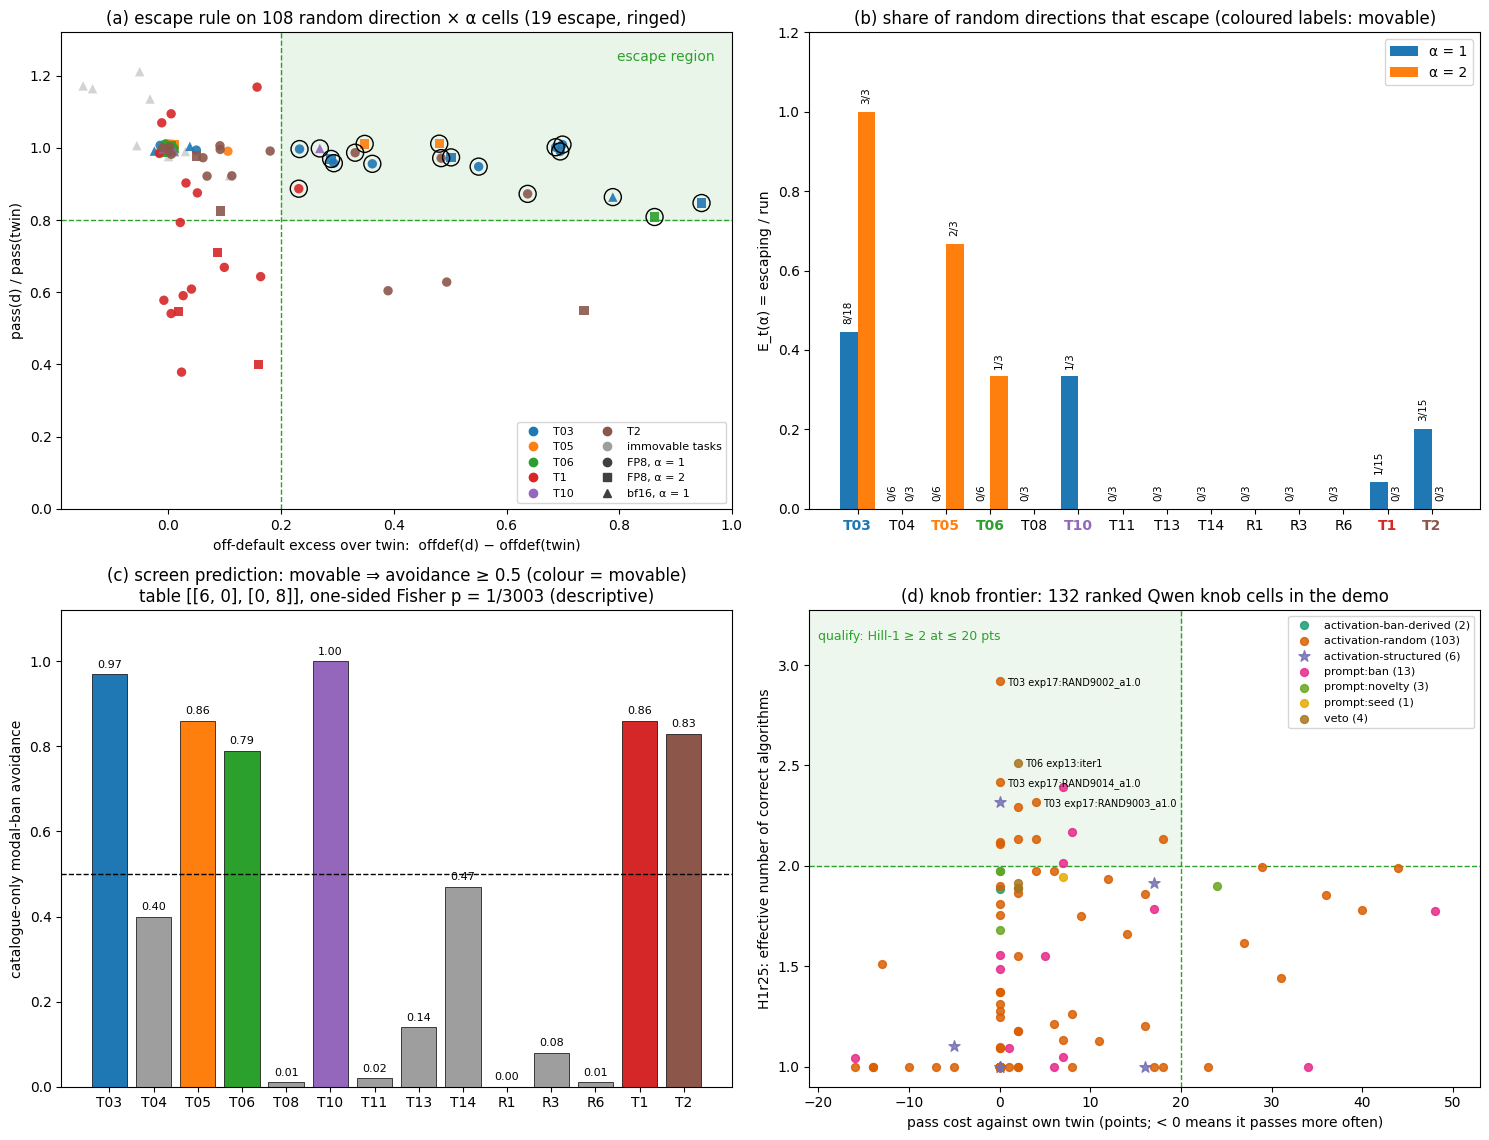

In [24]:
from matplotlib.lines import Line2D

rule = _load_rule()
d = pd.DataFrame(extras["per_direction_rows"])
d["escape"] = [rule.escape_of(r)[0] for r in extras["per_direction_rows"]]
d["excess"] = (1 - d.n_default / d.n_attempted) - (1 - d.twin_n_default / d.twin_n_attempted)
d["pass_ratio"] = (d.n_passed / d.n) / (d.twin_n_passed / d.twin_n)
movable = core["movable_tasks"]
col = dict(zip(movable, plt.cm.tab10.colors))
gray = "0.62"
jit = np.random.default_rng(0)
x = np.arange(len(QWEN14))

fig, axes = plt.subplots(2, 2, figsize=(15, 11.5))

# (a) the escape rule
ax = axes[0, 0]
ax.add_patch(plt.Rectangle((0.2, 0.8), 5, 5, color="tab:green", alpha=0.10, zorder=0))
ax.axvline(0.2, color="tab:green", ls="--", lw=1)
ax.axhline(0.8, color="tab:green", ls="--", lw=1)
mk = {("hf-fp8", 1.0): "o", ("hf-fp8", 2.0): "s", ("hf-bf16", 1.0): "^"}
for (t, eng, a), g in d.groupby(["task", "engine", "alpha"]):
    xs = g.excess + jit.uniform(-0.012, 0.012, len(g))
    ys = g.pass_ratio.clip(0, 1.3) + jit.uniform(-0.012, 0.012, len(g))
    ax.scatter(xs, ys, marker=mk[(eng, a)], s=46, facecolors=col.get(t, gray), edgecolors="none",
               alpha=0.9 if t in col else 0.45, zorder=3 if t in col else 2)
    ax.scatter(xs[g.escape], ys[g.escape], marker="o", s=150, facecolors="none", edgecolors="k", linewidths=1.0, zorder=4)
ax.text(0.97, 1.27, "escape region", ha="right", va="top", color="tab:green", fontsize=10, transform=ax.transData)
ax.set_xlim(min(-0.1, d.excess.min() - 0.05), max(1.0, d.excess.max() + 0.05))
ax.set_ylim(0, 1.32)
ax.set_xlabel("off-default excess over twin:  offdef(d) − offdef(twin)")
ax.set_ylabel("pass(d) / pass(twin)")
ax.set_title(f"(a) escape rule on {len(d)} random direction × α cells ({int(d.escape.sum())} escape, ringed)")
handles = [Line2D([], [], marker="o", ls="", color=col[t], label=t) for t in movable]
handles += [Line2D([], [], marker="o", ls="", color=gray, label="immovable tasks")]
handles += [Line2D([], [], marker=m, ls="", color="0.25", label=f"{'FP8' if e == 'hf-fp8' else 'bf16'}, α = {a:g}")
            for (e, a), m in mk.items()]
ax.legend(handles=handles, loc="lower right", fontsize=8, ncol=2)

# (b) E_t per task and alpha
ax = axes[0, 1]
w = 0.4
for k, (a, c_) in enumerate(((1, "tab:blue"), (2, "tab:orange"))):
    first = True
    for i, t in enumerate(QWEN14):
        ra = core["tasks"][t][f"alpha_{a}"]
        if not ra["n_directions_run"]:
            continue
        xi = i + (k - 0.5) * w
        ax.bar(xi, ra["E_t"], w, color=c_, label=f"α = {a}" if first else None)
        ax.text(xi, ra["E_t"] + 0.02, f"{ra['n_escape']}/{ra['n_directions_run']}", ha="center", va="bottom",
                fontsize=7.5, rotation=90)
        first = False
ax.set_xticks(x, QWEN14)
for lab in ax.get_xticklabels():
    if lab.get_text() in col:
        lab.set_color(col[lab.get_text()]); lab.set_fontweight("bold")
ax.set_ylim(0, 1.2)
ax.set_ylabel("E_t(α) = escaping / run")
ax.set_title("(b) share of random directions that escape (coloured labels: movable)")
ax.legend(loc="upper right")

# (c) catalogue-only modal-ban avoidance vs movability
ax = axes[1, 0]
av = [core["tasks"][t]["cat_only_ban_avoidance"] for t in QWEN14]
ax.bar(x, av, color=[col.get(t, gray) for t in QWEN14], edgecolor="k", linewidth=0.5)
ax.axhline(0.5, color="k", ls="--", lw=1)
for i, v in enumerate(av):
    ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, QWEN14)
ax.set_ylim(0, 1.12)
ax.set_ylabel("catalogue-only modal-ban avoidance")
ax.set_title(f"(c) screen prediction: movable ⇒ avoidance ≥ 0.5 (colour = movable)\n"
             f"table {fis['table']}, one-sided Fisher p = 1/{1 / fis['p']:.0f} (descriptive)")

# (d) the knob frontier: Hill-1 against pass cost, ranked Qwen knob cells
ax = axes[1, 1]
kq = knob[(knob["class"] == "knob") & knob.model.str.startswith("Qwen") & knob.H1r25.notna() & knob.pass_cost_pts.notna()]
fams = sorted(kq.family.unique())
fcol = dict(zip(fams, plt.cm.Dark2.colors))
ax.add_patch(plt.Rectangle((-100, 2.0), 120, 10, color="tab:green", alpha=0.08, zorder=0))
ax.axvline(20, color="tab:green", ls="--", lw=1)
ax.axhline(2.0, color="tab:green", ls="--", lw=1)
for f in fams:
    g = kq[kq.family == f]
    ax.scatter(g.pass_cost_pts, g.H1r25, s=70 if f == "activation-structured" else 32, color=fcol[f], alpha=0.85,
               marker="*" if f == "activation-structured" else "o", label=f"{f} ({len(g)})", zorder=3)
placed = []  # label the four most diverse cells, skipping any whose label would overlap one already placed
for _, r in kq.sort_values("H1r25", ascending=False).iterrows():
    if len(placed) == 4:
        break
    if any(abs(r.pass_cost_pts - px) < 18 and abs(r.H1r25 - py) < 0.07 for px, py in placed):
        continue
    placed.append((r.pass_cost_pts, r.H1r25))
    ax.annotate(f"{r.task} {r.exp}:{r.arm}", (r.pass_cost_pts, r.H1r25), fontsize=7, xytext=(5, -3),
                textcoords="offset points")
ax.set_xlim(kq.pass_cost_pts.min() - 5, kq.pass_cost_pts.max() + 5)
ax.set_ylim(0.9, kq.H1r25.max() + 0.35)
ax.text(kq.pass_cost_pts.min() - 4, kq.H1r25.max() + 0.2, "qualify: Hill-1 ≥ 2 at ≤ 20 pts", color="tab:green", fontsize=9)
ax.set_xlabel("pass cost against own twin (points; < 0 means it passes more often)")
ax.set_ylabel("H1r25: effective number of correct algorithms")
ax.set_title(f"(d) knob frontier: {len(kq)} ranked Qwen knob cells in the demo")
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

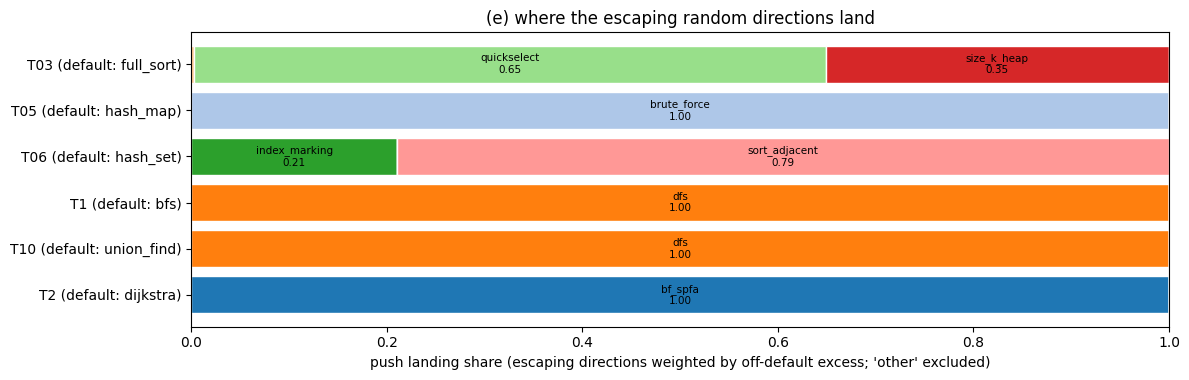

push landing per movable task:
   T03: quickselect 0.65, size_k_heap 0.35, heapify_pop 0.00
   T05: brute_force 1.00
   T06: sort_adjacent 0.79, index_marking 0.21
    T1: dfs 1.00
   T10: dfs 1.00
    T2: bf_spfa 1.00


In [25]:
# (e) push landing of the escaping directions, per movable task
fig, ax = plt.subplots(figsize=(12, 3.9))
algs = sorted({a for t in movable for a in core["tasks"][t]["push_landing"]})
acol = dict(zip(algs, plt.cm.tab20.colors))
yy = np.arange(len(movable))
left = np.zeros(len(movable))
for a in algs:
    v = np.array([core["tasks"][t]["push_landing"].get(a, 0.0) for t in movable])
    ax.barh(yy, v, left=left, color=acol[a], edgecolor="w", label=a)
    for yi, (vi, li) in enumerate(zip(v, left)):
        if vi >= 0.07:
            ax.text(li + vi / 2, yi, f"{a}\n{vi:.2f}", ha="center", va="center", fontsize=7.5)
    left += v
ax.set_yticks(yy, [f"{t} (default: {default_of(t)})" for t in movable])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("push landing share (escaping directions weighted by off-default excess; 'other' excluded)")
ax.set_title("(e) where the escaping random directions land")
plt.tight_layout()
plt.show()

print("push landing per movable task:")
for t in movable:
    land = core["tasks"][t]["push_landing"]
    print(f"  {t:>4}: " + ", ".join(f"{a} {v:.2f}" for a, v in sorted(land.items(), key=lambda kv: -kv[1])))

## What the demo reproduces, and what it leaves out

**Reproduced from 10,050 labelled programs, at the original settings**
- All 174 recomputed knob cells (of the artifact's 1,120) match the recorded table on every recorded field.
- The screen's sha256 equals the frozen value, and the stdlib rule reproduces it on its own from `screen_input.json`.
- The movable set is T03, T05, T06, T1, T10 and T2, which is exactly the frozen C1 set.
- The movable × avoidance table is 6/0/0/8.
- The random-direction counts and Table 110 match the record.
- 25 of the 27 verification targets reproduce, with the same two corrections as the full run. `immovable_six` is recomputed on the demo's cells only.

**What the numbers say**
- Where a random push moves Qwen at all, it lands on another *catalogue* algorithm: quickselect or a size-k heap for k-th smallest, brute force for two sum, sort-then-scan (and some index marking) for find duplicate, DFS for path search and for connected components, and BF/SPFA for weighted shortest path.
- These six are exactly the tasks on which a modal "do not use X" ban sends at least half of the attempted programs to another catalogue algorithm. On the other eight tasks no random direction escapes, and fewer than half of the programs written under a ban land on another catalogue algorithm.
- On T03 and T05 the cheapest qualifying row is a norm-matched *random* direction: exp17 RAND9002, at 0 points. The structured ADD edit does no better. On T03 its Hill-1 of 2.32 sits inside the random directions' range (1.00–2.92). On two sum it leaves the default untouched (avoidance 0.00) and costs 52 points.
- The immovable side is weakly tested. Most of those tasks have only K = 3 directions, which gives a 90% upper bound of 0.54 on their per-direction escape rate.
- This is a screen, not a confirmation: the rule was read off the same data.

**Not in this demo.** These stages need dependency files that the demo data does not carry:
- `inventory`: hashes of the declared input files
- `judges` and `other`: the blind LLM judges and the 'other' audit
- `route`: route landing (exp16)
- `llama`: the Llama hit rules
- `figures`: activation-space geometry from exp9 states
- `rigor`, `wording` and `rivals`
- `audit`: the stdlib re-derivations and placebos
- `outputs`: the `exp_eval_sol_out` files

Their results are in the artifact's `full_eval_out.json`, `results/` and `tables/`. To run everything with the dependency folders present (about 1.5 minutes): `uv sync --frozen && uv run eval.py --stages all`.